# Speed Traps in Aachen - Notebook

This notebook accompanies the assignment PDF. **The PDF contains the task descriptions**; here you only find the
question / part / subpart headers (e.g. `4(c)(i)` = Question 4, part (c), subpart (i)), short reminders, and the code
scaffold. Look for `TODO` and `...` to see what you have to fill in.

* Run the notebook from top to bottom. Use `SEED = 0` wherever randomness is involved.
* `helpers.py` and the folder `data/` must lie next to this notebook.
* Written answers and the figures you discuss belong into the **report**; where a subpart needs no code, the header says so.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import helpers
from helpers import DATA_DIR, BLUE, BLUE_RAMP

SEED = 0

In [2]:
# Utility (optional): call `save_and_show("name")` instead of `plt.show()` to also save the figures as figures/fig-name.svg and .pdf for your report. Set SAVE_FIGURES = False to disable saving.
from pathlib import Path

SAVE_FIGURES = True   # set to False to only show the figures
FIGURE_DIR = Path('figures')
_figure_count = {}


def save_and_show(label: str) -> None:
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for fig_num in plt.get_fignums():
            _figure_count[label] = _figure_count.get(label, 0) + 1
            name = label if _figure_count[label] == 1 else f"{label}-{_figure_count[label]}"
            for fmt in ('svg', 'pdf'):
                plt.figure(fig_num).savefig(FIGURE_DIR / f"fig-{name}.{fmt}", bbox_inches="tight")
    plt.show()
    plt.close("all")  # non-interactive backends (e.g. Agg in CI) keep figures open; avoid re-saving them in later cells

---
# Question 1 - Visualization

## 1(a)

In [3]:
# TODO
# Loading the trap_deployments.csv as a panda's dataframe
df_trap_deployments = pd.read_csv(f"{DATA_DIR}/trap_deployments.csv")
df_trap_deployments

,Datum,Strasse,fahrzeuge,verstoesse
0,2020-10-01,Hohenstaufenallee,581,79
1,2020-10-01,Schurzelter Straße,347,47
2,2020-10-01,Von-Coels-Straße,1054,10
3,2020-10-02,Passstraße,207,16
4,2020-10-05,Eupener Straße,589,54
...,...,...,...,...
2559,2026-06-30,Auf der Hüls,385,29
2560,2026-06-30,Eupener Straße,539,84
2561,2026-06-30,Peterstraße,2171,49
2562,2026-06-30,Prager Ring,2307,16


In [4]:
# TODO
# Getting an overview of the trap_deployments dataframe with the describe method
df_trap_deployments.describe()

,fahrzeuge,verstoesse
count,2564.000000,2564.000000
mean,733.479329,35.707098
std,654.012620,37.521418
min,12.000000,0.000000
25%,298.750000,12.000000
50%,541.500000,24.000000
75%,964.250000,45.000000
max,5635.000000,360.000000


## 1(b)

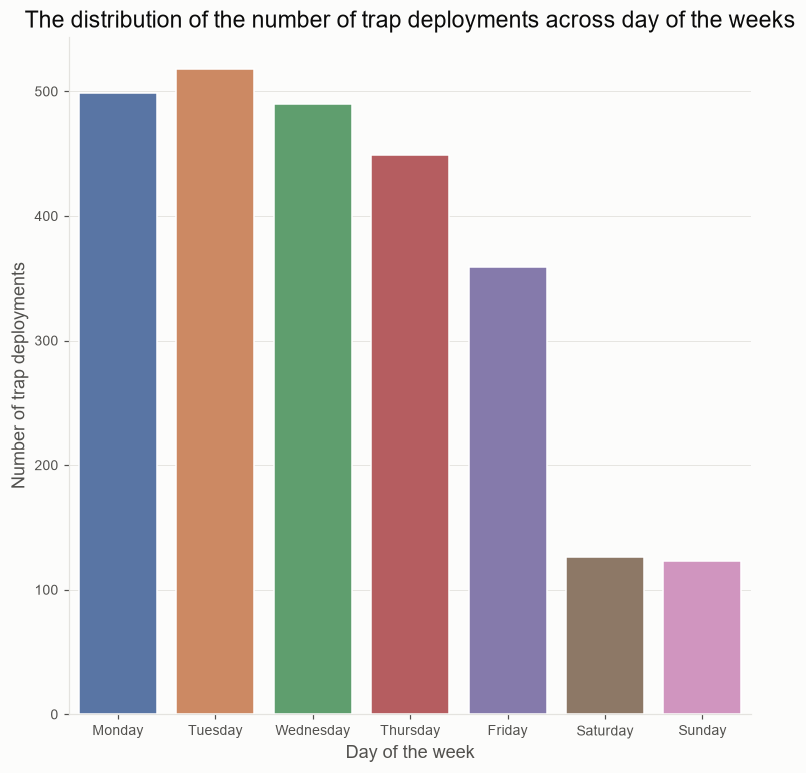

In [5]:
"""
We first extract the day of the week from the Datumn column into a separate "day" column by converting the column from string to datetime and then obtaining the day of the week with the day_name() function
"""
df_trap_deployments["day_of_the_week"] = pd.to_datetime(df_trap_deployments["Datum"]).dt.day_name()

# We group by "day" here in the column and then get the number of trap deployments with the size() aggregation
trap_number_plot = df_trap_deployments.groupby("day_of_the_week").size()

# Reorder the day of the week for better viewing
cats = ["Monday", "Tuesday", "Wednesday", 
        "Thursday", "Friday", "Saturday",
        "Sunday"]
trap_number_plot = trap_number_plot.reindex(cats).reset_index(name="Trap Deployment Count")


# Then, we create a bar plot with the days and the number of recorded trap deployments
fig, ax = plt.subplots(figsize=(8,8))
sns.set_theme(style="whitegrid", font="Times New Roman")

ax = sns.barplot(data=trap_number_plot, x="day_of_the_week", y="Trap Deployment Count", hue="day_of_the_week")

ax.set_title("The distribution of the number of trap deployments across day of the weeks", fontsize=15)
ax.set_xlabel("Day of the week", fontsize=12)
ax.set_ylabel("Number of trap deployments", fontsize=12)

plt.show()

## 1(c)

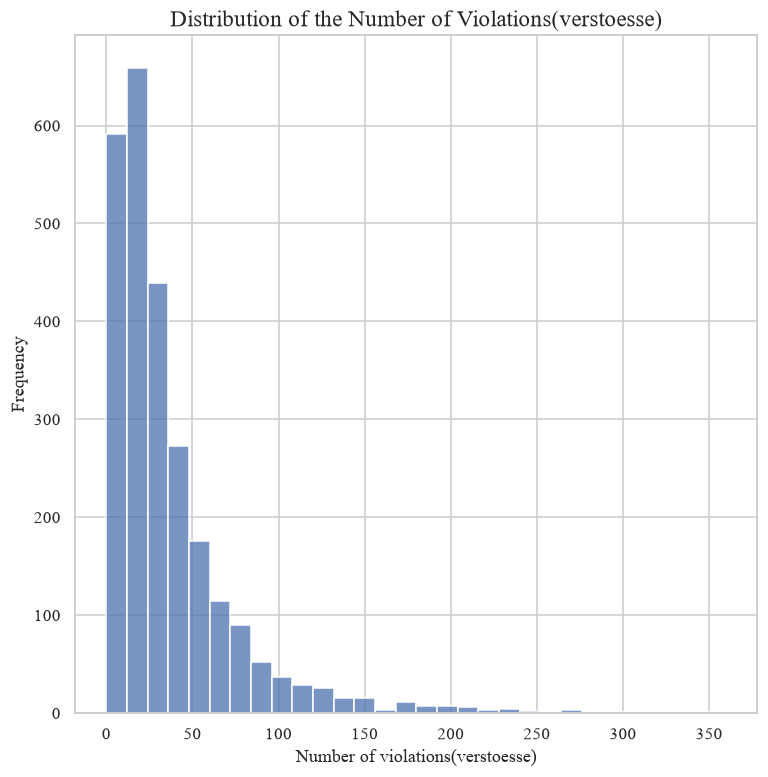

In [6]:
"""
    We analyze the distribution of the verstoesse feature by creating a histogram
"""
fig, ax = plt.subplots(figsize=(8,8))

sns.set_theme(style="whitegrid", font="Times New Roman")
sns.histplot(df_trap_deployments, x="verstoesse",bins=30, legend=False)
ax.set_title("Distribution of the Number of Violations(verstoesse)", fontsize=15)
ax.set_xlabel("Number of violations(verstoesse)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

plt.show()

## 1(d)

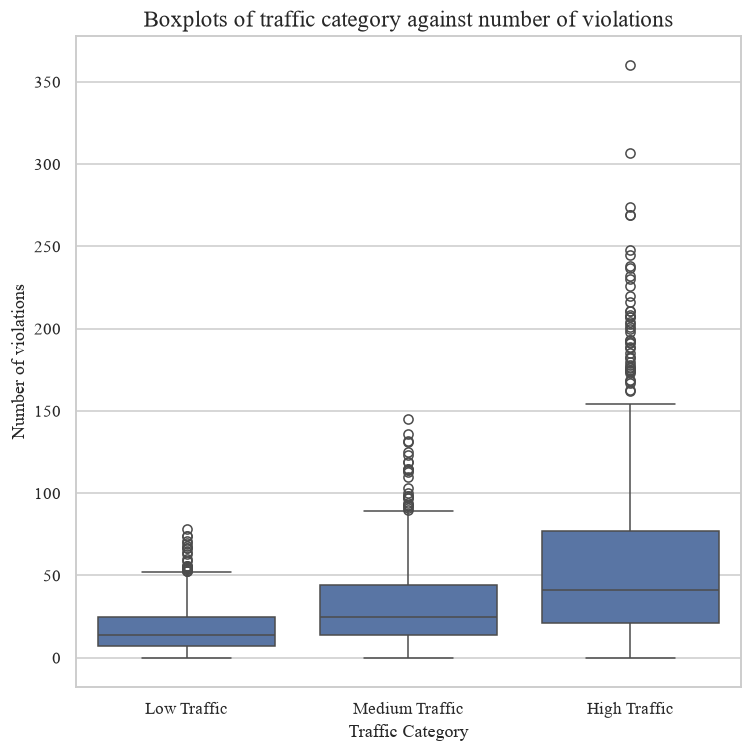

In [7]:
"""
    We first divide the dataset into three categoiries using the qcut function and also visualize using boxplot 
"""
df_trap_deployments["traffic_category"] = pd.qcut(x= df_trap_deployments["fahrzeuge"], q=3, labels=["Low Traffic", "Medium Traffic", "High Traffic"])

# Then, we create the boxplots for each traffic category 
fig,ax = plt.subplots(figsize=(7,7))
sns.set_theme(style="whitegrid", font="Times New Roman")

sns.boxplot(df_trap_deployments, x="traffic_category", y="verstoesse")
ax.set_title('Boxplots of traffic category against number of violations',fontsize=15)
ax.set_xlabel("Traffic Category", fontsize=12)
ax.set_ylabel("Number of violations", fontsize=12)

plt.tight_layout()
plt.show()

---
# Question 2 - Clustering

## 2(a)

## i)

In [8]:
# Loading the dataset for street_nodes.csv
df_street_nodes = pd.read_csv(f"{DATA_DIR}/street_nodes.csv")
display(df_street_nodes)

# Extract the original position for each row to use later
df_street_nodes["original_position"] = df_street_nodes.index
display(df_street_nodes)

,Strasse,achseid,startdista,x,y
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06
1,Horbacher Straße,2476967,0.00,292712.058378,5.633672e+06
2,Horbacher Straße,618774,981.34,292712.790053,5.633669e+06
3,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06
4,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06
...,...,...,...,...,...
2967,Oberforstbacher Straße,351904,201.81,300236.920519,5.623557e+06
2968,Rombachstraße,3434,365.77,299345.499559,5.625872e+06
2969,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06
2970,Nordstraße,2554,2474.76,300483.075669,5.628295e+06


,Strasse,achseid,startdista,x,y,original_position
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0
1,Horbacher Straße,2476967,0.00,292712.058378,5.633672e+06,1
2,Horbacher Straße,618774,981.34,292712.790053,5.633669e+06,2
3,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3
4,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4
...,...,...,...,...,...,...
2967,Oberforstbacher Straße,351904,201.81,300236.920519,5.623557e+06,2967
2968,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968
2969,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969
2970,Nordstraße,2554,2474.76,300483.075669,5.628295e+06,2970


In [9]:
# Create a data frame that contains all the centroids for each street by perofmring a group by with a mean aggregation function
df_centroids = df_street_nodes.groupby("Strasse")[["x", "y"]].agg("mean").reset_index()
df_centroids

,Strasse,x,y
0,Aachener Straße,298940.788655,5.622884e+06
1,Aachener-und-Münchener-Allee,293692.475663,5.627239e+06
2,Adalbertsteinweg,296061.975398,5.628581e+06
3,Adenauerallee,296586.773471,5.627142e+06
4,Albert-Einstein-Straße,300714.680585,5.621229e+06
...,...,...,...
155,Wilhelm-Ziemons-Straße,299294.614864,5.625261e+06
156,Wolfsbendenstraße,299249.332845,5.629940e+06
157,Würselener Straße,297703.556830,5.631605e+06
158,Zehnthofweg,298312.087981,5.629132e+06


In [10]:
# We extract the achseids with the largest startdistance for each street 
df_largest_startdista = df_street_nodes.groupby(['Strasse'])['startdista'].agg("max").reset_index()
df_largest_achseid = df_street_nodes.merge(df_largest_startdista, on=["Strasse", "startdista"], how="inner")[["Strasse","achseid","startdista"]]
df_largest_achseid

,Strasse,achseid,startdista
0,Nonnenhofstraße,2936,948.25
1,Horbacher Straße,2476857,4316.70
2,Hergenrather Weg,1375,1170.16
3,Alte Vaalser Straße,2902,1148.16
4,Laurensberger Straße,2940,3556.55
...,...,...,...
155,Forckenbeckstraße,3425,799.58
156,Seffenter Weg,1872,2099.55
157,Aretzstraße,1286,504.76
158,Aachener-und-Münchener-Allee,2230,325.91


In [11]:
# Join with df_largest_achseid with df_street_nodes to perform comparison
df_street_max_diff = df_street_nodes.merge(df_largest_achseid, on=['Strasse','achseid'], how="inner", suffixes=("","_max"))
df_street_max_diff

,Strasse,achseid,startdista,x,y,original_position,startdista_max
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0,2470.74
1,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3,948.25
2,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4,948.25
3,Nonnenhofstraße,2936,153.46,289249.638731,5.631802e+06,5,948.25
4,Nonnenhofstraße,2936,328.99,289103.239769,5.631705e+06,6,948.25
...,...,...,...,...,...,...,...
1862,Branderhofer Weg,2033,1369.02,295437.983563,5.627386e+06,2955,1546.06
1863,Forster Weg,1277,137.93,295643.984082,5.626949e+06,2957,1034.21
1864,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968,689.59
1865,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969,2987.78


In [12]:
# Calculate the absolute distance of the startdistance for each street node to (largest_startdista / 2)
df_street_max_diff["distance_to_middle"] = np.abs((df_street_max_diff["startdista_max"] / 2) - df_street_max_diff["startdista"])
df_street_max_diff

,Strasse,achseid,startdista,x,y,original_position,startdista_max,distance_to_middle
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0,2470.74,1230.840
1,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3,948.25,474.125
2,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4,948.25,474.125
3,Nonnenhofstraße,2936,153.46,289249.638731,5.631802e+06,5,948.25,320.665
4,Nonnenhofstraße,2936,328.99,289103.239769,5.631705e+06,6,948.25,145.135
...,...,...,...,...,...,...,...,...
1862,Branderhofer Weg,2033,1369.02,295437.983563,5.627386e+06,2955,1546.06,595.990
1863,Forster Weg,1277,137.93,295643.984082,5.626949e+06,2957,1034.21,379.175
1864,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968,689.59,20.975
1865,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969,2987.78,426.050


In [13]:
# We sort our values for each street and also the distance of the node to midway point
df_street_max_diff = df_street_max_diff.sort_values(["Strasse","startdista","distance_to_middle"])
df_street_max_diff

,Strasse,achseid,startdista,x,y,original_position,startdista_max,distance_to_middle
1628,Aachener Straße,350327,0.00,300723.981044,5.621352e+06,2468,4380.19,2190.095
1650,Aachener Straße,350327,134.07,300606.638414,5.621410e+06,2493,4380.19,2056.025
1634,Aachener Straße,350327,365.63,300384.595307,5.621459e+06,2475,4380.19,1824.465
1422,Aachener Straße,350327,1206.79,299946.004614,5.622143e+06,2159,4380.19,983.305
1423,Aachener Straße,350327,1586.82,299631.603264,5.622354e+06,2160,4380.19,603.275
...,...,...,...,...,...,...,...,...
1473,Zehntweg,2596,377.70,299776.550007,5.625185e+06,2244,529.85,112.775
1474,Zehntweg,2596,419.15,299813.128584,5.625205e+06,2246,529.85,154.225
1475,Zehntweg,2596,461.84,299853.219927,5.625219e+06,2248,529.85,196.915
1476,Zehntweg,2596,500.29,299890.182012,5.625230e+06,2250,529.85,235.365


In [14]:
# We obtain the closest node for each street
df_closest_to_halfway = df_street_max_diff.groupby(["Strasse", "achseid"])["distance_to_middle"].agg("min").reset_index()
df_closest_to_halfway

,Strasse,achseid,distance_to_middle
0,Aachener Straße,350327,6.575
1,Aachener-und-Münchener-Allee,2230,95.885
2,Adalbertsteinweg,2000,6.160
3,Adenauerallee,2003,32.855
4,Albert-Einstein-Straße,3223,16.035
...,...,...,...
155,Wilhelm-Ziemons-Straße,3436,18.220
156,Wolfsbendenstraße,3488,36.990
157,Würselener Straße,2812,7.250
158,Zehnthofweg,1989,2.795


In [15]:
# Now we merge once more with the streets with the largest achseid to get the smallest distance_to_middle
df_middle_nodes = df_street_max_diff.merge(df_closest_to_halfway,on=["Strasse","achseid","distance_to_middle"],how="inner")
# We drop any nodes with equal distances and take the first occuring node from the original df
df_middle_nodes = df_middle_nodes.sort_values(by=["original_position"])
df_middle_nodes = df_middle_nodes.drop_duplicates(subset=["distance_to_middle"])
df_middle_nodes

,Strasse,achseid,startdista,x,y,original_position,startdista_max,distance_to_middle
112,Nonnenhofstraße,2936,328.99,289103.239769,5.631705e+06,6,948.25,145.135
45,Hergenrather Weg,1375,188.70,290857.633078,5.623067e+06,33,1170.16,396.380
8,Alte Vaalser Straße,2902,522.23,290441.084983,5.628343e+06,50,1148.16,51.850
142,Schurzelter Straße,2985,2160.65,291078.699900,5.630050e+06,75,4694.35,186.525
159,Vetschauer Weg,2750,1267.34,291550.894925,5.633839e+06,81,2470.74,31.970
...,...,...,...,...,...,...,...,...
70,Kaubendenstraße,3489,39.23,299435.334399,5.627664e+06,2873,507.74,214.640
155,Trierer Straße,2123,2723.22,298914.152424,5.626599e+06,2880,5498.30,25.930
72,Kesselstraße,3318,409.11,297420.535615,5.621693e+06,2953,752.30,32.960
125,Raafstraße,3321,358.86,297253.856200,5.621969e+06,2954,685.48,16.120


In [16]:
# Extract the coords for the middle nodes
df_middle_nodes = df_middle_nodes[["Strasse","x", "y"]]
df_middle_nodes

,Strasse,x,y
112,Nonnenhofstraße,289103.239769,5.631705e+06
45,Hergenrather Weg,290857.633078,5.623067e+06
8,Alte Vaalser Straße,290441.084983,5.628343e+06
142,Schurzelter Straße,291078.699900,5.630050e+06
159,Vetschauer Weg,291550.894925,5.633839e+06
...,...,...,...
70,Kaubendenstraße,299435.334399,5.627664e+06
155,Trierer Straße,298914.152424,5.626599e+06
72,Kesselstraße,297420.535615,5.621693e+06
125,Raafstraße,297253.856200,5.621969e+06


In [17]:
# Now we verify our middle nodes with the fallback_street_coor.csv
df_fallback_street = pd.read_csv(f"{DATA_DIR}/fallback_street_coor.csv")
df_fallback_street

,Strasse,x,y,n_knoten
0,Aachener Straße,299061.153580,5.622606e+06,43
1,Aachener-und-Münchener-Allee,293708.749974,5.627178e+06,3
2,Adalbertsteinweg,296074.999072,5.628719e+06,18
3,Adenauerallee,296347.780698,5.626963e+06,49
4,Albert-Einstein-Straße,300723.979499,5.621352e+06,16
...,...,...,...,...
155,Wilhelm-Ziemons-Straße,299292.979449,5.625279e+06,25
156,Wolfsbendenstraße,299259.569042,5.629992e+06,10
157,Würselener Straße,297694.193190,5.631592e+06,6
158,Zehnthofweg,298348.820217,5.629150e+06,33


In [18]:
# We merge both the dataframes for comparison
df_verify = df_fallback_street.merge(df_middle_nodes[["Strasse","x","y"]], on=["Strasse"], how="inner", suffixes=("_fallback", "_middle"))
# Calculate the euclidean distance between the fallback street node and our middle node to obtain the difference
df_verify["difference"] = np.sqrt(np.square(df_verify["x_fallback"] - df_verify["x_middle"]) + np.square(df_verify["y_fallback"] - df_verify["y_middle"]))
df_verify

,Strasse,x_fallback,y_fallback,n_knoten,x_middle,y_middle,difference
0,Aachener Straße,299061.153580,5.622606e+06,43,299061.153580,5.622606e+06,0.0
1,Aachener-und-Münchener-Allee,293708.749974,5.627178e+06,3,293708.749974,5.627178e+06,0.0
2,Adalbertsteinweg,296074.999072,5.628719e+06,18,296074.999072,5.628719e+06,0.0
3,Adenauerallee,296347.780698,5.626963e+06,49,296347.780698,5.626963e+06,0.0
4,Albert-Einstein-Straße,300723.979499,5.621352e+06,16,300723.979499,5.621352e+06,0.0
...,...,...,...,...,...,...,...
155,Wilhelm-Ziemons-Straße,299292.979449,5.625279e+06,25,299292.979449,5.625279e+06,0.0
156,Wolfsbendenstraße,299259.569042,5.629992e+06,10,299259.569042,5.629992e+06,0.0
157,Würselener Straße,297694.193190,5.631592e+06,6,297694.193190,5.631592e+06,0.0
158,Zehnthofweg,298348.820217,5.629150e+06,33,298348.820217,5.629150e+06,0.0


## ii)

In [19]:
df_street_nodes_centroid = df_street_nodes.merge(df_centroids, on=["Strasse"], how="inner", suffixes=('_original', "_centroid"))
df_street_nodes_centroid

,Strasse,achseid,startdista,x_original,y_original,original_position,x_centroid,y_centroid
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0,291582.325771,5.633689e+06
1,Horbacher Straße,2476967,0.00,292712.058378,5.633672e+06,1,292148.984524,5.634601e+06
2,Horbacher Straße,618774,981.34,292712.790053,5.633669e+06,2,292148.984524,5.634601e+06
3,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3,289019.812869,5.631649e+06
4,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4,289019.812869,5.631649e+06
...,...,...,...,...,...,...,...,...
2967,Oberforstbacher Straße,351904,201.81,300236.920519,5.623557e+06,2967,299588.079520,5.623228e+06
2968,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968,299173.412243,5.625993e+06
2969,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969,299883.385178,5.631001e+06
2970,Nordstraße,2554,2474.76,300483.075669,5.628295e+06,2970,300116.665885,5.627177e+06


In [20]:
df_street_nodes_centroid["difference"] = np.sqrt(np.square(df_street_nodes_centroid["x_original"] - df_street_nodes_centroid["x_centroid"]) + np.square(df_street_nodes_centroid["y_original"] - df_street_nodes_centroid["y_centroid"]))
df_street_nodes_centroid

,Strasse,achseid,startdista,x_original,y_original,original_position,x_centroid,y_centroid,difference
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0,291582.325771,5.633689e+06,1119.335433
1,Horbacher Straße,2476967,0.00,292712.058378,5.633672e+06,1,292148.984524,5.634601e+06,1086.533612
2,Horbacher Straße,618774,981.34,292712.790053,5.633669e+06,2,292148.984524,5.634601e+06,1088.803923
3,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3,289019.812869,5.631649e+06,516.249465
4,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4,289019.812869,5.631649e+06,429.232680
...,...,...,...,...,...,...,...,...,...
2967,Oberforstbacher Straße,351904,201.81,300236.920519,5.623557e+06,2967,299588.079520,5.623228e+06,727.344820
2968,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968,299173.412243,5.625993e+06,210.185337
2969,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969,299883.385178,5.631001e+06,572.769816
2970,Nordstraße,2554,2474.76,300483.075669,5.628295e+06,2970,300116.665885,5.627177e+06,1177.342062


In [21]:
df_street_nodes_middle = df_street_nodes.merge(df_middle_nodes, on=["Strasse"], how="inner", suffixes=('_original', "_middle"))
df_street_nodes_middle

,Strasse,achseid,startdista,x_original,y_original,original_position,x_middle,y_middle
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0,291550.894925,5.633839e+06
1,Horbacher Straße,2476967,0.00,292712.058378,5.633672e+06,1,291790.530337,5.635591e+06
2,Horbacher Straße,618774,981.34,292712.790053,5.633669e+06,2,291790.530337,5.635591e+06
3,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3,289103.239769,5.631705e+06
4,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4,289103.239769,5.631705e+06
...,...,...,...,...,...,...,...,...
2967,Oberforstbacher Straße,351904,201.81,300236.920519,5.623557e+06,2967,299195.113825,5.623432e+06
2968,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968,299345.499559,5.625872e+06
2969,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969,300020.973864,5.630918e+06
2970,Nordstraße,2554,2474.76,300483.075669,5.628295e+06,2970,300275.376235,5.627213e+06


In [22]:
df_street_nodes_middle["difference"] = np.sqrt(np.square(df_street_nodes_middle["x_original"] - df_street_nodes_middle["x_middle"]) + np.square(df_street_nodes_middle["y_original"] - df_street_nodes_middle["y_middle"]))
df_street_nodes_middle

,Strasse,achseid,startdista,x_original,y_original,original_position,x_middle,y_middle,difference
0,Vetschauer Weg,2750,2466.21,292701.551543,5.633674e+06,0,291550.894925,5.633839e+06,1162.409194
1,Horbacher Straße,2476967,0.00,292712.058378,5.633672e+06,1,291790.530337,5.635591e+06,2129.420418
2,Horbacher Straße,618774,981.34,292712.790053,5.633669e+06,2,291790.530337,5.635591e+06,2131.730391
3,Nonnenhofstraße,2936,948.25,288590.543128,5.631362e+06,3,289103.239769,5.631705e+06,616.747704
4,Nonnenhofstraße,2936,0.00,289380.388923,5.631882e+06,4,289103.239769,5.631705e+06,328.755508
...,...,...,...,...,...,...,...,...,...
2967,Oberforstbacher Straße,351904,201.81,300236.920519,5.623557e+06,2967,299195.113825,5.623432e+06,1049.326759
2968,Rombachstraße,3434,365.77,299345.499559,5.625872e+06,2968,299345.499559,5.625872e+06,0.000000
2969,Verlautenheidener Straße,2852,1067.84,300383.427020,5.630722e+06,2969,300020.973864,5.630918e+06,412.193866
2970,Nordstraße,2554,2474.76,300483.075669,5.628295e+06,2970,300275.376235,5.627213e+06,1102.404734


In [23]:
print(f"The median difference (Centroid): {df_street_nodes_centroid["difference"].median()}")
print(f"The maximum difference (Centroid): {df_street_nodes_centroid["difference"].max()}")
print(f"The median difference (Middle Nodes): {df_street_nodes_middle["difference"].median()}")
print(f"The maximum difference (Middle Nodes): {df_street_nodes_middle["difference"].max()}")

The median difference (Centroid): 304.14626207303587
The maximum difference (Centroid): 5711.974192567312
The median difference (Middle Nodes): 345.7203195999128
The maximum difference (Middle Nodes): 4724.795067076799


In [24]:
print(df_street_nodes_centroid[df_street_nodes_centroid["difference"] == df_street_nodes_centroid["difference"].max()].head(1))
print(df_street_nodes_middle[df_street_nodes_middle["difference"] == df_street_nodes_middle["difference"].max()].head(1))

                Strasse  achseid  startdista     x_original    y_original  \
2425  Monschauer Straße   608055         0.0  300738.868712  5.618778e+06   

      original_position     x_centroid    y_centroid   difference  
2425               2425  297105.268373  5.623186e+06  5711.974193  
               Strasse  achseid  startdista     x_original    y_original  \
859  Monschauer Straße   608055    10029.79  295310.030641  5.626309e+06   

     original_position       x_middle      y_middle   difference  
859                859  297532.211167  5.622139e+06  4724.795067  


In [25]:
# We merge the coordinates for centroid and middle nodes
df_street_nodes_plot = df_street_nodes_centroid[["Strasse", "x_original", "y_original", "x_centroid", "y_centroid"]].merge(df_street_nodes_middle[["Strasse", "x_original", "y_original", "x_middle", "y_middle"]], on=["Strasse", "x_original", "y_original"], how="inner")

# Since the street is Monschauer strasse we filter specifically for that street
df_street_nodes_plot = df_street_nodes_plot[df_street_nodes_plot["Strasse"] == "Monschauer Straße"]
df_street_nodes_plot

,Strasse,x_original,y_original,x_centroid,y_centroid,x_middle,y_middle
913,Monschauer Straße,295310.030641,5.626309e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1182,Monschauer Straße,296128.130540,5.624594e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1183,Monschauer Straße,295967.578997,5.624921e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1184,Monschauer Straße,295967.578743,5.624921e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1185,Monschauer Straße,295946.811445,5.625055e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1186,Monschauer Straße,295946.811599,5.625055e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1187,Monschauer Straße,295452.427870,5.626112e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1188,Monschauer Straße,295386.014610,5.626192e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1189,Monschauer Straße,295569.697922,5.625938e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06
1190,Monschauer Straße,295633.843259,5.625779e+06,297105.268373,5.623186e+06,297532.211167,5.622139e+06


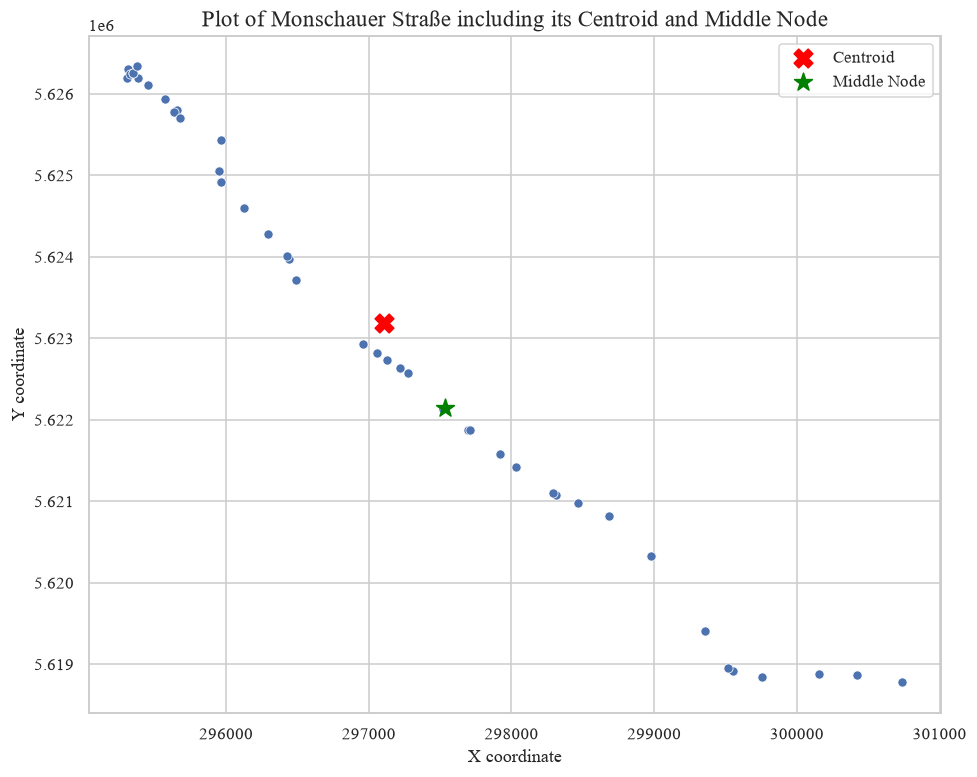

In [26]:
fig, ax = plt.subplots(figsize=(10,8))

sns.scatterplot(df_street_nodes_plot, x="x_original", y="y_original", ax=ax)
sns.set_theme(style="whitegrid", font="Times New Roman")
# Plot the point for centroid
ax.scatter(297105.2683726215, 5623185.5889242515, color="red", marker="X", s=150, label="Centroid")
# Plot the point for middle node
ax.scatter(297532.2111665166, 5622139.498921193, color="green", marker="*", s=150, label="Middle Node")
ax.set_xlabel("X coordinate",fontsize=12)
ax.set_ylabel("Y coordinate",fontsize=12)
ax.set_title("Plot of Monschauer Straße including its Centroid and Middle Node",fontsize=15)

ax.legend()
plt.show()

## 2(b)

In [27]:
# TODO
sum_of_squared_errors = []
silhouette_scores = []
for k in range(2,21):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(df_middle_nodes[["x","y"]])
    sum_of_squared_errors.append(kmeans.inertia_) # inertia contains the sum of squared errors of the fitted k-means
    silhouette_scores.append(silhouette_score(df_middle_nodes[["x","y"]], kmeans.labels_,)) # We use labels_ to get all the clusters for each street node

df_kmeans = pd.DataFrame({
    "k": range(2,21),
    "sum_of_squared_errors": sum_of_squared_errors,
    "silhouette_scores": silhouette_scores
})
df_kmeans

,k,sum_of_squared_errors,silhouette_scores
0,2,1.498301e+09,0.445949
1,3,9.604450e+08,0.398021
2,4,7.209456e+08,0.401920
3,5,5.676520e+08,0.384915
4,6,4.616612e+08,0.375540
5,7,4.031324e+08,0.359372
6,8,3.434033e+08,0.378056
7,9,3.073946e+08,0.376405
8,10,2.703493e+08,0.387058
9,11,2.406296e+08,0.395640


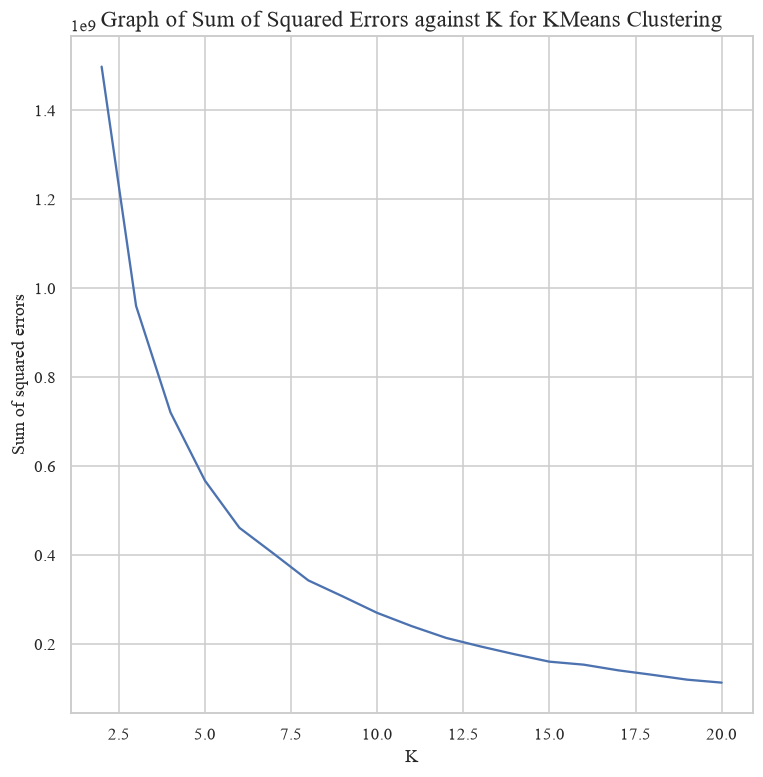

In [28]:
fig,ax = plt.subplots(figsize=(8,8))

sns.set_theme(style="whitegrid",font="Times New Roman")

sns.lineplot(df_kmeans, x="k", y="sum_of_squared_errors")
ax.set_xlabel("K",fontsize=12)
ax.set_ylabel("Sum of squared errors",fontsize=12)
ax.set_title("Graph of Sum of Squared Errors against K for KMeans Clustering",fontsize=15)

plt.show()

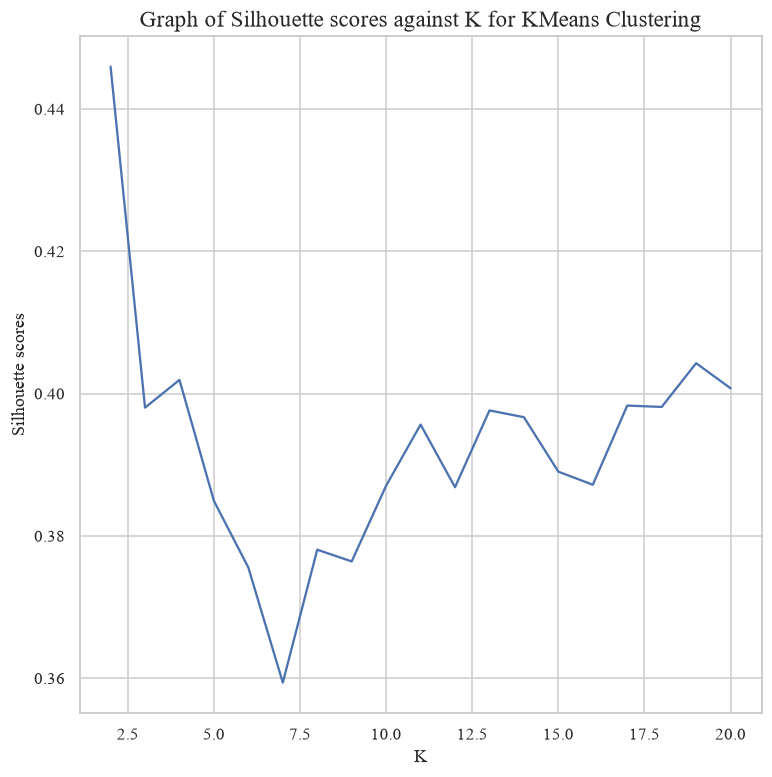

In [29]:
fig,ax = plt.subplots(figsize=(8,8))

sns.set_theme(style="whitegrid",font="Times New Roman")

sns.lineplot(df_kmeans, x="k", y="silhouette_scores")
ax.set_xlabel("K",fontsize=12)
ax.set_ylabel("Silhouette scores",fontsize=12)
ax.set_title("Graph of Silhouette scores against K for KMeans Clustering",fontsize=15)

plt.show()

## 2(c)

## i)

In [30]:
# TODO
kmeans_8 = KMeans(n_clusters=8, n_init=20, random_state=SEED).fit(df_middle_nodes[["x","y"]])

df_kmeans8 = df_middle_nodes.copy()
df_kmeans8["cluster_no"] = kmeans_8.labels_
display(df_kmeans8)

# We first calculate the number of middle_nodes per cluster
# Then, we rank them based on the number of nodes per cluster in descending order 
df_region_grouped = df_kmeans8.groupby("cluster_no")["Strasse"].nunique().sort_values(ascending=False).reset_index(name="middle_nodes_count")
df_region_grouped["cluster_rank"] = range(len(df_region_grouped)) # We can use range here since each row is already ordered in descending order in terms of the middle_nodes_count.
display(df_region_grouped)

# Now we create new dataframe for plotting the regions
df_kmeans8_region = df_kmeans8.merge(df_region_grouped, on="cluster_no", how="inner")
display(df_kmeans8_region)

,Strasse,x,y,cluster_no
112,Nonnenhofstraße,289103.239769,5.631705e+06,2
45,Hergenrather Weg,290857.633078,5.623067e+06,0
8,Alte Vaalser Straße,290441.084983,5.628343e+06,7
142,Schurzelter Straße,291078.699900,5.630050e+06,7
159,Vetschauer Weg,291550.894925,5.633839e+06,2
...,...,...,...,...
70,Kaubendenstraße,299435.334399,5.627664e+06,1
155,Trierer Straße,298914.152424,5.626599e+06,3
72,Kesselstraße,297420.535615,5.621693e+06,6
125,Raafstraße,297253.856200,5.621969e+06,6


,cluster_no,middle_nodes_count,cluster_rank
0,4,30,0
1,1,25,1
2,7,24,2
3,3,22,3
4,6,17,4
5,5,16,5
6,2,14,6
7,0,12,7


,Strasse,x,y,cluster_no,middle_nodes_count,cluster_rank
0,Nonnenhofstraße,289103.239769,5.631705e+06,2,14,6
1,Hergenrather Weg,290857.633078,5.623067e+06,0,12,7
2,Alte Vaalser Straße,290441.084983,5.628343e+06,7,24,2
3,Schurzelter Straße,291078.699900,5.630050e+06,7,24,2
4,Vetschauer Weg,291550.894925,5.633839e+06,2,14,6
...,...,...,...,...,...,...
155,Kaubendenstraße,299435.334399,5.627664e+06,1,25,1
156,Trierer Straße,298914.152424,5.626599e+06,3,22,3
157,Kesselstraße,297420.535615,5.621693e+06,6,17,4
158,Raafstraße,297253.856200,5.621969e+06,6,17,4


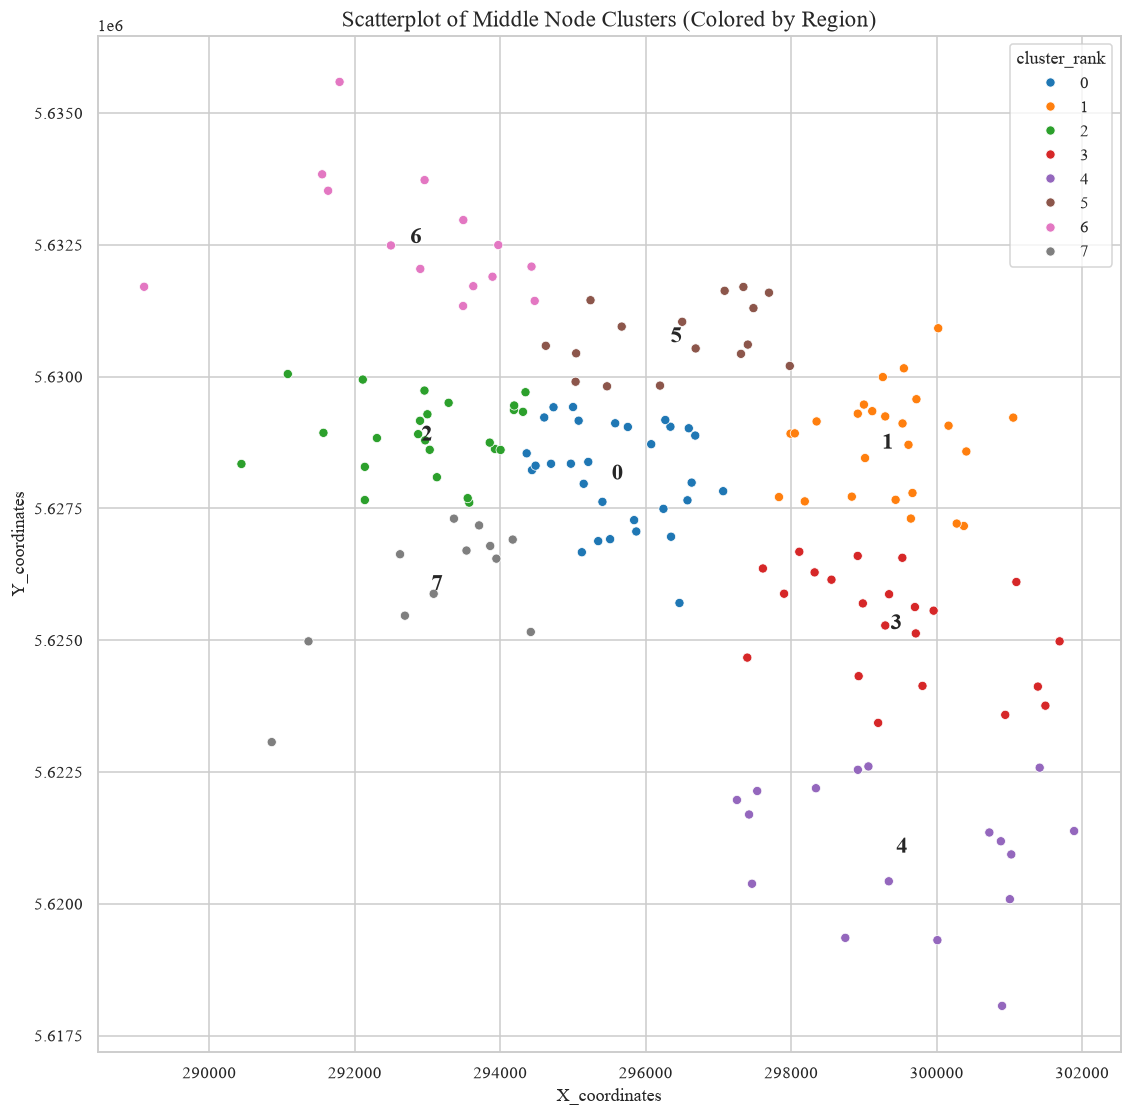

In [31]:
fig,ax = plt.subplots(figsize=(12,12))

sns.set_theme(style='whitegrid', font="Times New Roman")

# Plotting the scatterplot for all the clusters
sns.scatterplot(df_kmeans8_region, x="x", y="y", hue="cluster_rank", palette="tab10", ax=ax)

# We plot the cluster centers by marking with the region number
for _, row in df_region_grouped.iterrows():
    cluster_no = int(row["cluster_no"])
    region_no = int(row["cluster_rank"])
    x_center, y_center = kmeans_8.cluster_centers_[cluster_no] # Obtain the centers of each cluster by using cluster_centers_

    ax.text(x_center, y_center, str(region_no), ha="center", va="center", fontsize=15, fontweight="bold")

ax.set_xlabel("X_coordinates",fontsize=12)
ax.set_ylabel("Y_coordinates",fontsize=12)
ax.set_title("Scatterplot of Middle Node Clusters (Colored by Region)", fontsize=15)
plt.show()

## ii)

In [32]:
df_total_street = df_kmeans8_region.groupby("cluster_rank")["Strasse"].count().reset_index(name="Count of Streets")
display(df_total_street)

df_trap_deployments = pd.read_csv(f"{DATA_DIR}/trap_deployments.csv")
display(df_trap_deployments)
df_total_traps = df_kmeans8_region.merge(df_trap_deployments, on="Strasse", how="inner")
df_total_traps = df_total_traps.groupby("cluster_rank")["Strasse"].count().reset_index(name='Count of Trap Deployments')
display(df_total_traps)

df_traps_share = (df_total_traps["Count of Trap Deployments"] / len(df_trap_deployments)) * 100
display(df_traps_share)

,cluster_rank,Count of Streets
0,0,30
1,1,25
2,2,24
3,3,22
4,4,17
5,5,16
6,6,14
7,7,12


,Datum,Strasse,fahrzeuge,verstoesse
0,2020-10-01,Hohenstaufenallee,581,79
1,2020-10-01,Schurzelter Straße,347,47
2,2020-10-01,Von-Coels-Straße,1054,10
3,2020-10-02,Passstraße,207,16
4,2020-10-05,Eupener Straße,589,54
...,...,...,...,...
2559,2026-06-30,Auf der Hüls,385,29
2560,2026-06-30,Eupener Straße,539,84
2561,2026-06-30,Peterstraße,2171,49
2562,2026-06-30,Prager Ring,2307,16


,cluster_rank,Count of Trap Deployments
0,0,579
1,1,286
2,2,314
3,3,311
4,4,175
5,5,417
6,6,139
7,7,343


0    22.581903
1    11.154446
2    12.246490
3    12.129485
4     6.825273
5    16.263651
6     5.421217
7    13.377535
Name: Count of Trap Deployments, dtype: float64

---
# Question 3 - Correlation

To reduce dependencies on the results of the preceding question, use the regions from `data/streets_to_regions_k8.csv` from here on.

In [33]:
trap_days = pd.read_csv(DATA_DIR / "trap_deployments.csv", parse_dates=["Datum"])
region_of = pd.read_csv(DATA_DIR / "streets_to_regions_k8.csv", index_col="Strasse")["region"]
trap_days["region"] = trap_days["Strasse"].map(region_of)

g = trap_days.groupby("Strasse").agg(days=("Datum", "size"), viol=("verstoesse", "sum"), veh=("fahrzeuge", "sum"))
streets_obs = pd.DataFrame({"days": g["days"], "yield": g["viol"] / g["days"],   # number of trap locations; mean violations per trap location
                            "vehicles": g["veh"] / g["days"],                     # mean vehicles per trap location
                            "rate": g["viol"] / g["veh"]})                        # violations per vehicle
streets_obs.head()

,days,yield,vehicles,rate
Strasse,,,,
Aachener Straße,16,24.312500,874.937500,0.027788
Aachener-und-Münchener-Allee,11,19.090909,431.090909,0.044285
Adalbertsteinweg,9,9.111111,879.111111,0.010364
Adenauerallee,32,14.843750,658.875000,0.022529
Albert-Einstein-Straße,2,22.500000,128.500000,0.175097


## 3(a) - Scatter plots

### 3(a)(i) - Street level

Scatter plot of the number of trap locations (log scale) against the mean violations per trap location; marker size or color: mean vehicles.

,days,yield,vehicles,rate
Strasse,,,,
Aachener Straße,16,24.312500,874.937500,0.027788
Aachener-und-Münchener-Allee,11,19.090909,431.090909,0.044285
Adalbertsteinweg,9,9.111111,879.111111,0.010364
Adenauerallee,32,14.843750,658.875000,0.022529
Albert-Einstein-Straße,2,22.500000,128.500000,0.175097
...,...,...,...,...
Wilhelm-Ziemons-Straße,6,4.500000,168.500000,0.026706
Wolfsbendenstraße,2,14.500000,395.000000,0.036709
Würselener Straße,17,24.647059,337.882353,0.072946


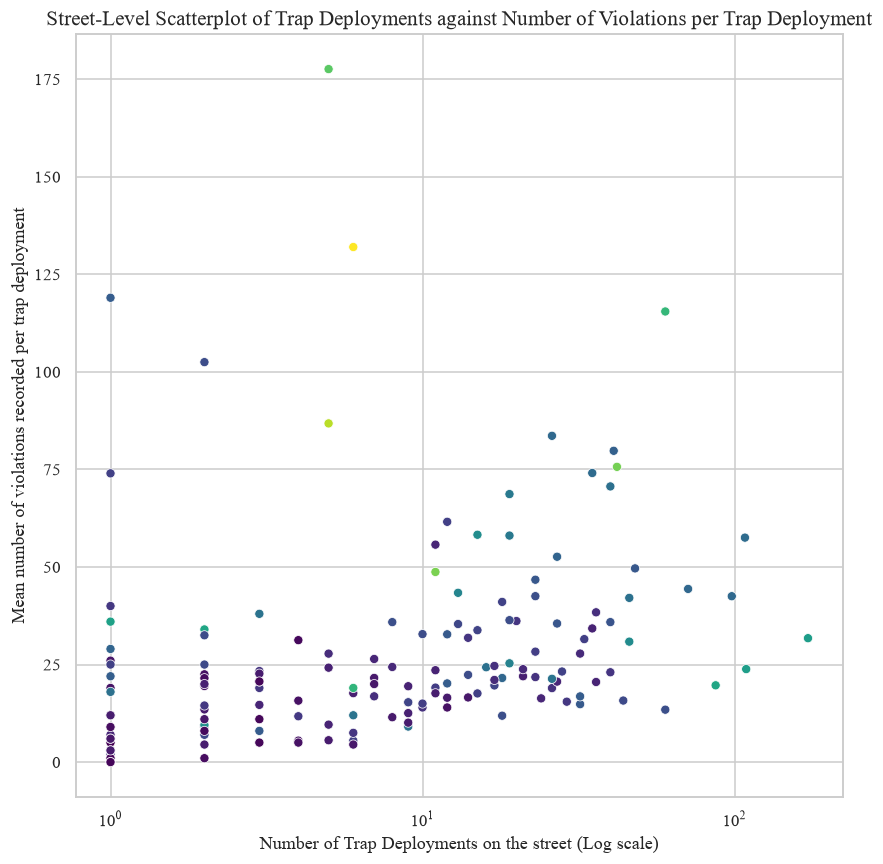

In [34]:
# `streets_obs` (one row per street) is given above.
# TODO: scatter plot
display(streets_obs)
fig,ax = plt.subplots(figsize=(9,9))

sns.set_theme(style="whitegrid", font='Times New Roman')

sns.scatterplot(streets_obs, x="days", y="yield", hue="vehicles", palette="viridis", ax=ax, legend=False)
ax.set_xlabel("Number of Trap Deployments on the street (Log scale)", fontsize=12)
ax.set_ylabel("Mean number of violations recorded per trap deployment",fontsize=12)
ax.set_title("Street-Level Scatterplot of Trap Deployments against Number of Violations per Trap Deployment", fontsize=14)
ax.set_xscale("log") # We set the x-axis to a logarithm scale
plt.show()

### 3(a)(ii) - Region level

Number of trap locations (linear scale) against the mean violations per trap location; label each point with its region; marker size or color: mean vehicles.

,Datum,Strasse,fahrzeuge,verstoesse,region
0,2020-10-01,Hohenstaufenallee,581,79,2
1,2020-10-01,Schurzelter Straße,347,47,2
2,2020-10-01,Von-Coels-Straße,1054,10,5
3,2020-10-02,Passstraße,207,16,1
4,2020-10-05,Eupener Straße,589,54,3
...,...,...,...,...,...
2559,2026-06-30,Auf der Hüls,385,29,1
2560,2026-06-30,Eupener Straße,539,84,3
2561,2026-06-30,Peterstraße,2171,49,0
2562,2026-06-30,Prager Ring,2307,16,1


,region,days,yield,vehicles,rate
0,0,502,50.627490,861.468127,0.058769
1,1,425,33.510588,902.710588,0.037122
2,2,391,36.051151,734.516624,0.049081
3,3,343,45.204082,640.501458,0.070576
4,4,311,22.678457,797.051447,0.028453
5,5,286,23.339161,509.975524,0.045765
6,6,175,26.805714,503.137143,0.053277
7,7,131,29.587786,579.076336,0.051095


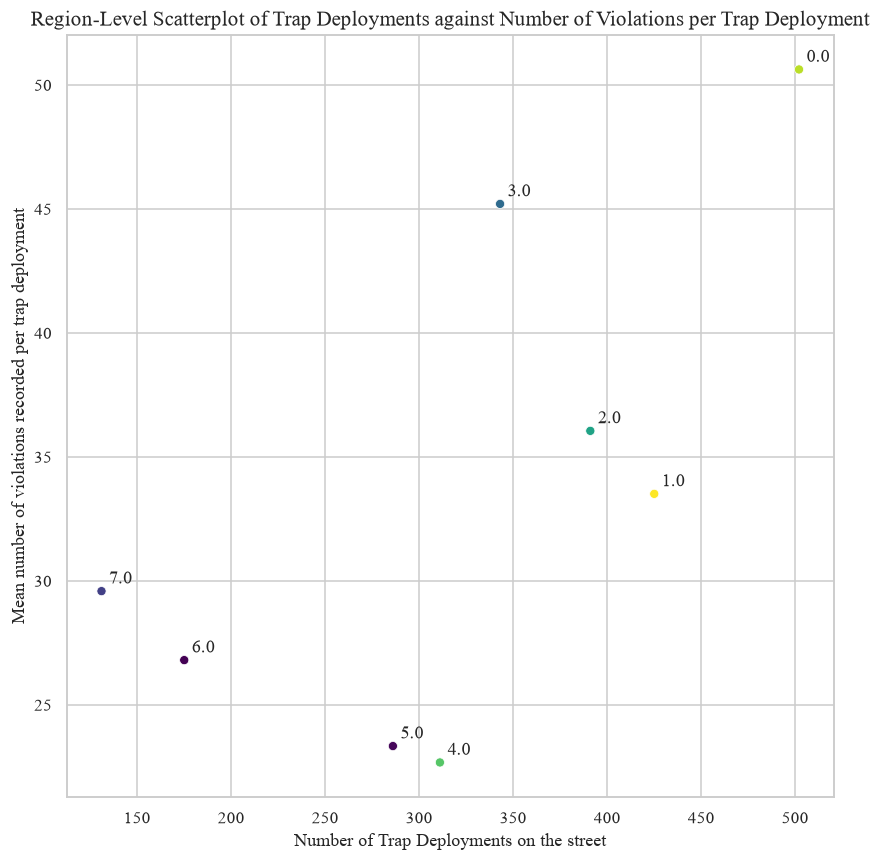

In [35]:
# `trap_days` already has a `region` column.
# TODO: aggregate per region, then scatter plot with region labels
# Join streets_obs and trap_days dataframe to have access to the region column for plotting
display(trap_days)
intermediate = trap_days.groupby("region").agg(days=("Datum","size"), viol=("verstoesse", "sum"), veh=("fahrzeuge", "sum")).reset_index()

df_region_level = pd.DataFrame({
                            "region": intermediate["region"],
                            "days": intermediate["days"], # number of trap locations
                            "yield": intermediate["viol"]/intermediate["days"], # mean violations per trap deployment
                            "vehicles": intermediate["veh"]/intermediate["days"], # mean vehicles per trap deployment
                            "rate": intermediate["viol"]/intermediate["veh"] # violations per vehicle
})
display(df_region_level)

fig,ax = plt.subplots(figsize=(9,9))

sns.set_theme(style="whitegrid", font='Times New Roman')

sns.scatterplot(df_region_level, x="days", y="yield", hue="vehicles", palette="viridis", ax=ax, legend=False)
ax.set_xlabel("Number of Trap Deployments on the street", fontsize=12)
ax.set_ylabel("Mean number of violations recorded per trap deployment",fontsize=12)
ax.set_title("Region-Level Scatterplot of Trap Deployments against Number of Violations per Trap Deployment", fontsize=14)

for _, row in df_region_level.iterrows():
    ax.annotate(row["region"], (row["days"], row["yield"]), xytext=(5,5), textcoords="offset points")

plt.show()

### 3(a)(iii) - Relation

*Answer in the report; no code needed.*

## 3(b) - Spearman's rank correlation

### 3(b)(i) - Coefficient

Spearman's rho between the number of trap locations of a street and its mean violations per trap location; only streets with at least 3 trap locations.

In [36]:
keep = streets_obs.index[streets_obs["days"] >= 3]
# TODO: Spearman's rank correlation for the streets in `keep` (hint: scipy.stats.spearmanr)
streets_obs_3 = streets_obs.loc[keep] # We filter the streets_obs dataframe for keep indexes
rho = stats.spearmanr(streets_obs_3["days"], streets_obs_3["yield"])
print(f"The Spearman's rho between the number of trap locations of a street and its mean violations per trap location; only streets with at least 3 trap locations: {rho.statistic}")
# TODO: the same for streets with at least 10 trap locations
keep10 = streets_obs.index[streets_obs["days"] >= 10] # Filter rows for only streets with at least 10 trap locations
streets_obs_10 = streets_obs.loc[keep10] # Then filter the streets_obs dataframe for keep10 indexes
rho10 = stats.spearmanr(streets_obs_10["days"], streets_obs_10["yield"])
print(f"The Spearman's rho between the number of trap locations of a street and its mean violations per trap location; only streets with at least 10 trap locations: {rho10.statistic}")

The Spearman's rho between the number of trap locations of a street and its mean violations per trap location; only streets with at least 3 trap locations: 0.4285212020974478
The Spearman's rho between the number of trap locations of a street and its mean violations per trap location; only streets with at least 10 trap locations: 0.222100495925239


### 3(b)(ii) - Confidence interval

The bootstrap code is given: run it and interpret the result in the report.

In [37]:
def spearman(table: pd.DataFrame, column: str, min_locations: int = 3) -> float:
    # Spearman's rho between the number of trap locations and `column`, for the streets with at least `min_locations` trap locations
    # TODO
    keep = table.index[table["days"] >= min_locations]
    table = table.loc[keep]

    return stats.spearmanr(table["days"], table[column]).statistic

In [38]:
def boot_spearman(column: str, n_boot: int = 1000, seed: int = SEED) -> np.ndarray:
    # Bootstrap over streets: draw the streets with replacement, recompute rho, repeat.
    rng = np.random.default_rng(seed)
    kept = streets_obs[streets_obs["days"] >= 3]
    out = []
    for _ in range(n_boot):
        sample = kept.iloc[rng.integers(0, len(kept), len(kept))]
        out.append(spearman(sample, column))
    return np.array(out)


boot = boot_spearman("yield")
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Spearman rho = {spearman(streets_obs, 'yield'):+.2f}, 95% bootstrap interval [{lo:+.2f}, {hi:+.2f}]")

Spearman rho = +0.43, 95% bootstrap interval [+0.15, +0.66]


## 3(c) - A second correlation analysis

Reuse `spearman` and `boot_spearman` from 3(b)(ii); `streets_obs` has the columns `days`, `yield`, `vehicles` and `rate`. Hint: violations per trap location = vehicles per trap location x violations per vehicle.

### 3(c)(i) - Choice of variables

*Answer in the report; no code needed.*

### 3(c)(ii) - Scatter plot

Same style as in 3(a)(i), one scatter plot for each pair of variables you chose.

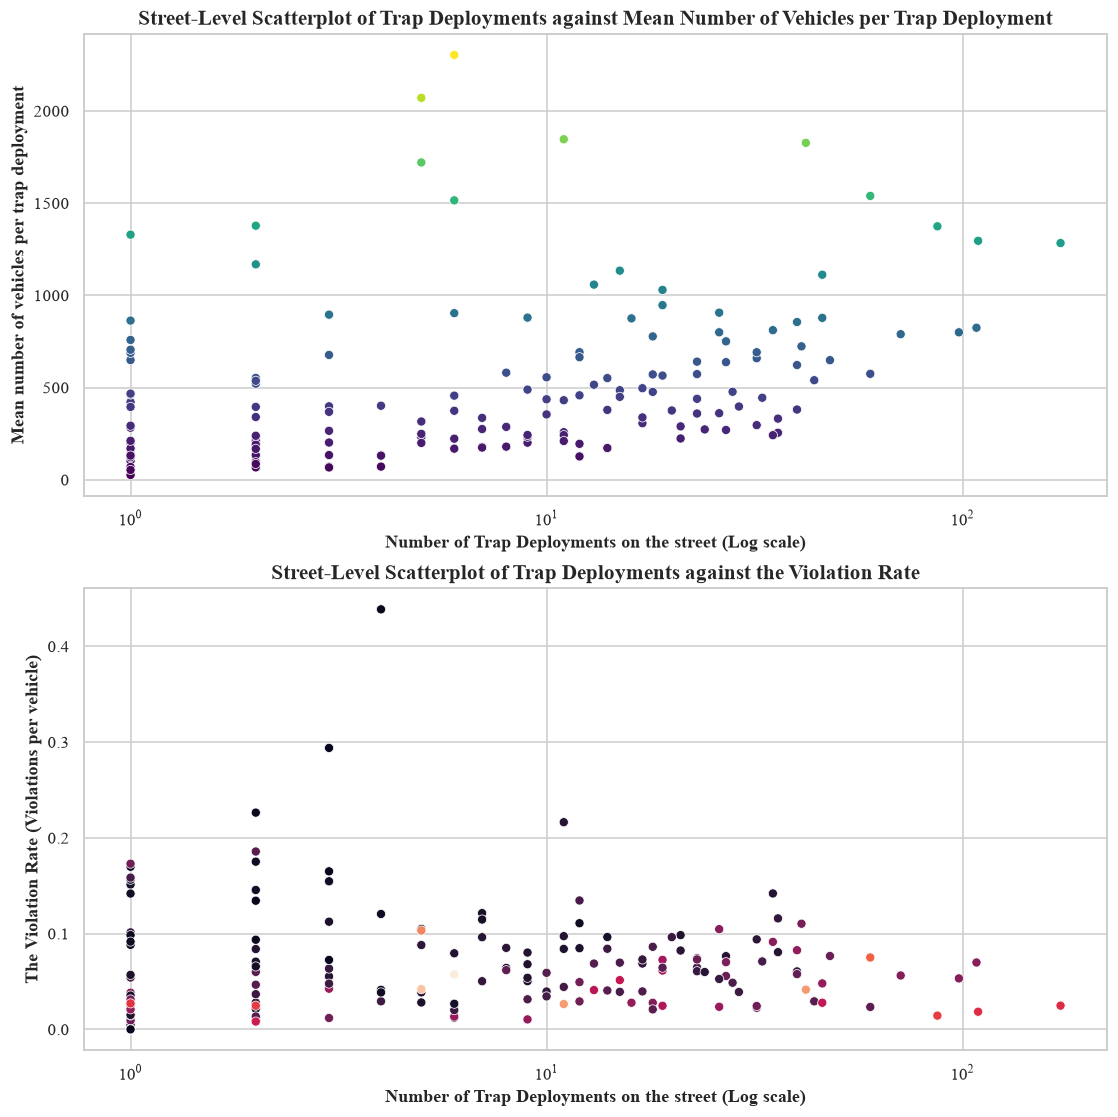

In [39]:
# TODO: scatter plots of the variables you chose
# Scatter plot for the variable pair of 
fig,ax = plt.subplots(2,1,figsize=(12,12))

sns.set_theme(style="whitegrid", font='Times New Roman')

# Scatterplot for "days" against "vehicles"
sns.scatterplot(streets_obs, x="days", y="vehicles", hue="vehicles", palette="viridis", ax=ax[0], legend=False)
ax[0].set_xlabel("Number of Trap Deployments on the street (Log scale)", fontsize=12, fontweight="bold")
ax[0].set_ylabel("Mean number of vehicles per trap deployment",fontsize=12, fontweight="bold")
ax[0].set_title("Street-Level Scatterplot of Trap Deployments against Mean Number of Vehicles per Trap Deployment", fontsize=14, fontweight="bold")
ax[0].set_xscale("log") # We set the x-axis to a logarithm scale

# Scatterplot for "days" against "rate"
sns.scatterplot(streets_obs, x="days", y="rate", hue="vehicles", palette="rocket", ax=ax[1], legend=False)
ax[1].set_xlabel("Number of Trap Deployments on the street (Log scale)", fontsize=12, fontweight="bold")
ax[1].set_ylabel("The Violation Rate (Violations per vehicle)",fontsize=12, fontweight="bold")
ax[1].set_title("Street-Level Scatterplot of Trap Deployments against the Violation Rate", fontsize=14, fontweight="bold")
ax[1].set_xscale("log") # We set the x-axis to a logarithm scale

plt.show()

### 3(c)(iii) - Coefficient and confidence interval

In [40]:
# TODO: Spearman's rho and its bootstrap interval for your variables
print(f"Number of trap deployments against mean vehicles per trap deployment:")
boot_vehicle = boot_spearman("vehicles")
lo, hi = np.percentile(boot_vehicle, [2.5, 97.5])
print(f"Spearman rho = {spearman(streets_obs, 'vehicles'):+.2f}, 95% bootstrap interval [{lo:+.2f}, {hi:+.2f}]")

print(f"Number of trap deployments against the violation rate:")
boot_violation = boot_spearman("rate")
lo, hi = np.percentile(boot_violation, [2.5, 97.5])
print(f"Spearman rho = {spearman(streets_obs, 'rate'):+.2f}, 95% bootstrap interval [{lo:+.2f}, {hi:+.2f}]")

Number of trap deployments against mean vehicles per trap deployment:
Spearman rho = +0.46, 95% bootstrap interval [+0.15, +0.68]
Number of trap deployments against the violation rate:
Spearman rho = -0.08, 95% bootstrap interval [-0.40, +0.24]


### 3(c)(iv) - Description of the results

*Answer in the report; no code needed.*

## 3(d) - Association versus motive

*Answer in the report; no code needed.*

---
# Question 4 - Predicting Speed Trap Locations

Regions are the instructor's K = 8 regions. The tables `hits` (measured day x region, 1 = at least one trap) and `n_traps` (traps per measured day) are given.

In [41]:
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import CategoricalNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, OrdinalEncoder, StandardScaler

trap_days = pd.read_csv(DATA_DIR / "trap_deployments.csv", parse_dates=["Datum"])
streets = pd.read_csv(DATA_DIR / "fallback_street_coor.csv", index_col="Strasse")
region_of = pd.read_csv(DATA_DIR / "streets_to_regions_k8.csv", index_col="Strasse")["region"]
trap_days["region"] = trap_days["Strasse"].map(region_of)

hits = pd.crosstab(trap_days["Datum"], trap_days["region"]).gt(0).astype(int)   # measured day x region, 0/1
n_traps = trap_days.groupby("Datum").size()                                       # traps per measured day
LAG_BINS = ["1", "2", "3", "4-7", "8+"]                                           # categories of the feature lag_bin
logit = lambda p: np.log(p / (1 - p))
hits.head()

region,0,1,2,3,4,5,6,7
Datum,,,,,,,,
2020-10-01,0,0,1,0,0,1,0,0
2020-10-02,0,1,0,0,0,0,0,0
2020-10-05,0,0,0,1,1,0,0,0
2020-10-06,1,0,0,0,0,1,0,0
2020-10-07,0,0,1,0,0,1,0,0


## 4(a) - Train/test split

### 4(a)(i) - Number of measured days

Test set = all measured days of season 2025/26 (from `helpers.TEST_START`); the rest is training data.

In [42]:
train_days = hits.index[hits.index < helpers.TEST_START]
test_days = hits.index[hits.index >= helpers.TEST_START]
# TODO: report the number of measured days in both sets
print(f"Number of measure days in train_set: {len(train_days)}")
print(f"Number of meausred days in test_set: {len(test_days)}")

Number of measure days in train_set: 368
Number of meausred days in test_set: 238


### 4(a)(ii) - Training rate (scalar value) of "trap in region"

Fraction of (training measured day, region) pairs with a trap.

In [43]:
hits_training = hits.loc[train_days]
total_entries = len(hits_training) * len(hits_training.columns) # We get the total amount of regions where a trap could be deployed
hits_training["num_traps_deployed"] = hits_training.sum(axis=1, numeric_only=True) # We create a new column that accumulates the total sum of traps deployed that day
total_traps_deployed = hits_training["num_traps_deployed"].sum(axis=0) # We obtain the total number of traps deployed across all training days
display(hits_training) 
rate = total_traps_deployed / total_entries # training rate of "trap in region" (use `hits` and `train_days`)
print(f"The training rate: {rate}")

region,0,1,2,3,4,5,6,7,num_traps_deployed
Datum,,,,,,,,,
2020-10-01,0,0,1,0,0,1,0,0,2
2020-10-02,0,1,0,0,0,0,0,0,1
2020-10-05,0,0,0,1,1,0,0,0,2
2020-10-06,1,0,0,0,0,1,0,0,2
2020-10-07,0,0,1,0,0,1,0,0,2
...,...,...,...,...,...,...,...,...,...
2024-12-13,0,0,1,0,0,0,0,0,1
2024-12-16,0,0,0,1,0,1,0,1,3
2024-12-17,1,1,0,1,0,0,1,0,4


The training rate: 0.39028532608695654


### 4(a)(iii) - Rate-based baseline

Always predict `rate` for every region and day; report its test log-loss.

In [44]:
# TODO: test log-loss of the rate-based baseline (sklearn.metrics.log_loss, `hits` of the test days as y_true)
hits_test = hits.loc[test_days]
# 1st Method that goes through each entry one by one and averages at the end
log_loss_summation = 0
for idx in hits_test.index:
    for col in hits_test.columns:
        log_loss_summation += log_loss([hits_test.loc[idx, col]], [rate], labels=[0,1]) # obtains the log-loss for each entry within the hits test_data and sum them

total_entries = len(hits_test) * len(hits_test.columns) # Calculate the total entries in the test set
test_log_loss = (1 / total_entries) * log_loss_summation # Divide the summation by the total entries to obtain an average test log-loss
print(f"The test-log-loss for the rate-based baseline is: {test_log_loss}") 

# 2nd Method to check if we obtain the same result (now using flatten, since log_loss automatically averages by all entries)
hits_test_flattened = np.array(hits_test).ravel()
rate_array = [rate] * len(hits_test_flattened)
test_log_loss2 = log_loss(hits_test_flattened, rate_array, labels=[0,1])
print(f"The test-log-loss (2nd-Method) for the rate-based baseline is: {test_log_loss2}") 

The test-log-loss for the rate-based baseline is: 0.6826752317126382
The test-log-loss (2nd-Method) for the rate-based baseline is: 0.6826752317126514


### 4(a)(iv) - Random splits for time series

*Answer in the report; no code needed.*

## 4(b) - Base features

Features: `logit_freq`, `lag_bin`, `weekday`. Use only days **strictly before** the current day. `LAG_BINS` and `logit` are defined above.

In [45]:
def rolling_freq(hits: pd.DataFrame, window: int) -> pd.DataFrame:
    # TODO: smoothed share of the previous `window` measured days with a hit (measured day x region)
    df_freq = hits.astype(float).copy() # We create a copy of the original hits dataset but with floats instead of integers

    for i, idx in enumerate(hits.index):
        for col in hits.columns:
            if i - window < 0: # if the window goes beyond the actual dataframe we set it to start from zero
                hits_window = hits.iloc[0:i]
            else:
                hits_window = hits.iloc[i-window: i]

            days = len(hits_window)
            num_hits = hits_window[col].sum(axis=0)

            smoothed_freq = (num_hits + 1) / (days + 2)

            df_freq.loc[idx, col] = smoothed_freq

    return df_freq

def base_frames(hits: pd.DataFrame, n_traps: pd.Series = None) -> dict:
    # TODO: return {"logit_freq": table (measured day x region), "lag_bin": table of strings (measured day x region),
    #               "weekday": Series (one value per measured day)}
    df_freq = rolling_freq(hits, 60) # Since we want a window of 60 days
    df_logit_freq = df_freq.apply(logit) # We apply the logit to every smoothed frequency cell

    df_lag_bin = pd.DataFrame("8+", index=hits.index, columns=hits.columns)

    for region in hits.columns:
        last_hit_date = None

        for date, hit in hits[region].items():
            # Calculate the today's feature using only previous hits
            if last_hit_date is not None:
                days_since = (date - last_hit_date).days

                if days_since <= 3:
                    df_lag_bin.loc[date, region] = str(days_since)
                elif days_since <= 7:
                    df_lag_bin.loc[date, region] = "4-7"
                # Otherwise we just keep the assigned "8+"

            if hit == 1:
                last_hit_date = date

    weekday_list = []
    for date in hits.index:
        weekday = date.day_of_week # Monday would equal to 0, .. Sunday = 6
        weekday_list.append(min(weekday, 5))

    weekday_series = pd.Series(weekday_list, index=hits.index)

    return {"logit_freq": df_logit_freq, "lag_bin": df_lag_bin, "weekday": weekday_series}

            
# Leakage check: removes the last days and verifies that the features of the earlier days stay the same.
helpers.check_no_leakage(base_frames, hits, n_traps)
# Long table: one row per (measured day, region); drops the first 20 days (too little history), adds `hit` and `split`.
df = helpers.to_long(base_frames(hits), hits)
train, test = (df[df["split"] == s] for s in ("train", "test"))
print(f"{len(train)} training rows ({train['hit'].mean():.1%} positive), {len(test)} test rows ({test['hit'].mean():.1%} positive)")
df.head()
# Backup: if you cannot implement the features, load them instead:
# df = pd.read_csv(DATA_DIR / "fallback_regression_k8.csv", parse_dates=["Datum"]); train, test = (df[df["split"] == s] for s in ("train", "test"))

OK: none of the 3 features uses information from later days.
2784 training rows (38.8% positive), 1904 test rows (42.1% positive)


,Datum,region,hit,logit_freq,lag_bin,weekday,split
0,2020-10-25,0,1,-0.367725,2,5,train
1,2020-10-25,1,0,-0.182322,1,5,train
2,2020-10-25,2,1,-0.367725,4-7,5,train
3,2020-10-25,3,0,0.182322,1,5,train
4,2020-10-25,4,0,0.000000,3,5,train


**Histograms of the three base features** (part of 4(b))

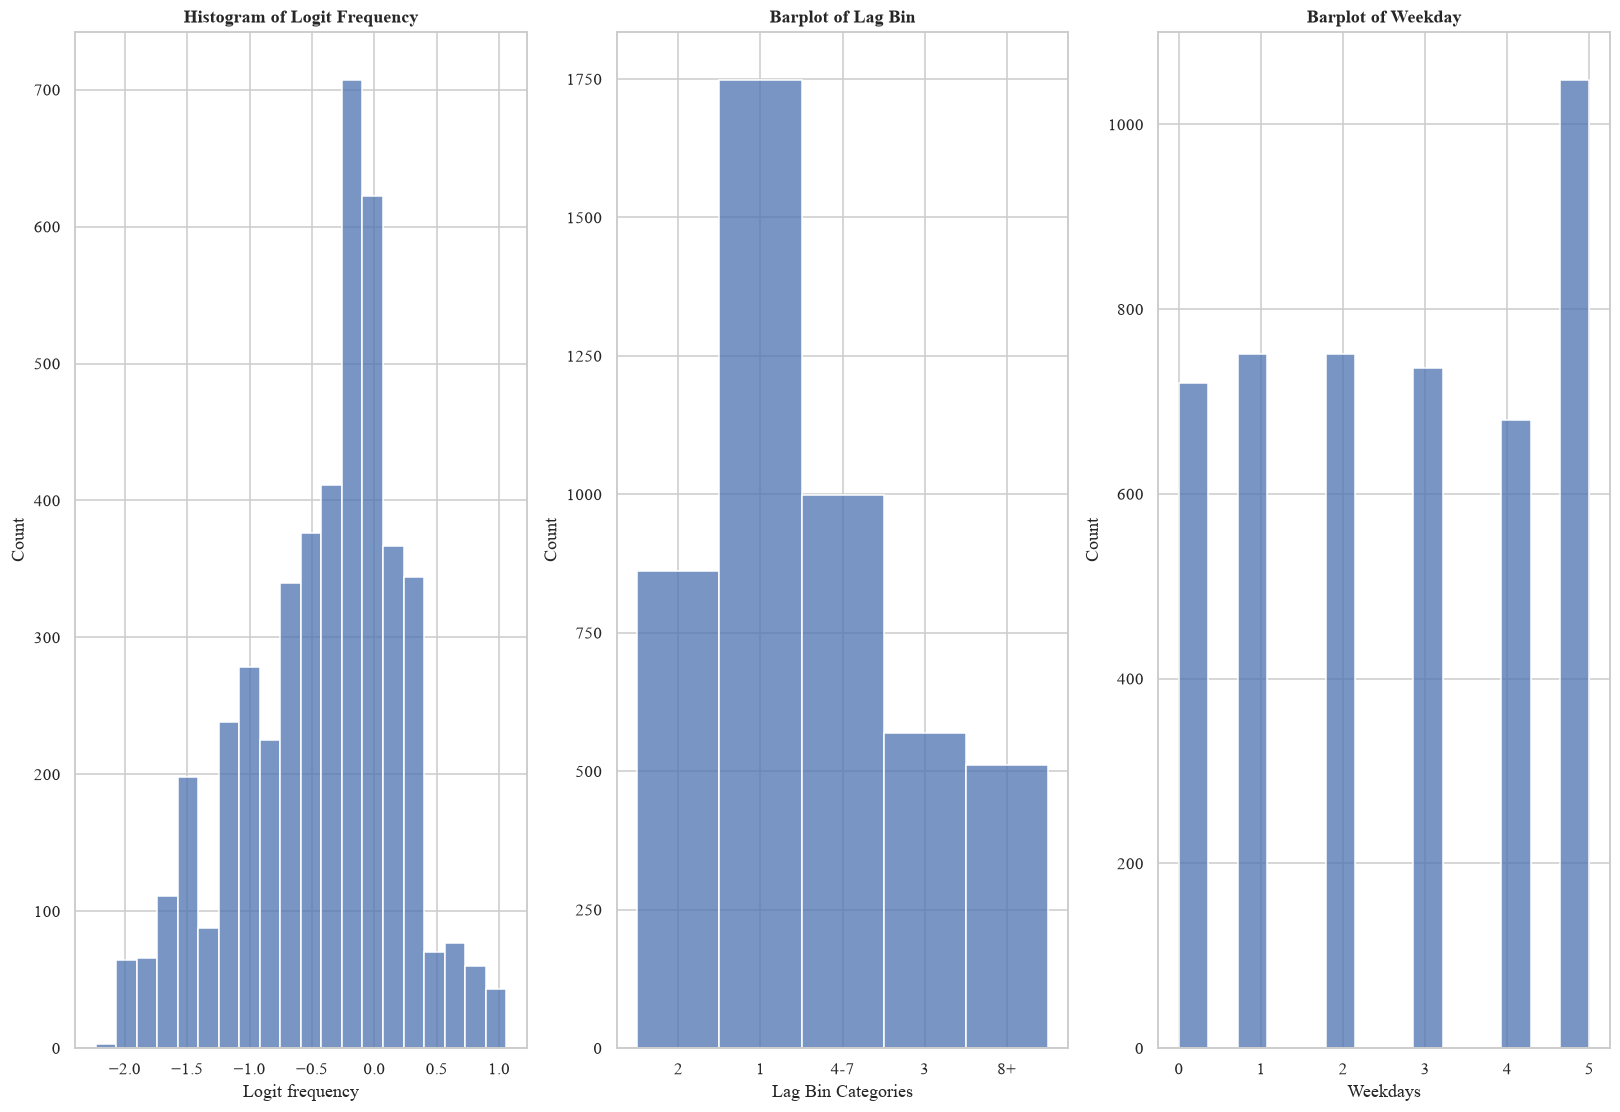

In [46]:
# TODO: one histogram (or bar chart for the categorical features) per base feature
fig, ax = plt.subplots(1,3, figsize=(18,12))

sns.set_theme(style="whitegrid", font="Times New Roman")

sns.histplot(df, x="logit_freq", bins=20,ax=ax[0])
ax[0].set_title("Histogram of Logit Frequency", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Logit frequency")

sns.histplot(df, x="lag_bin", ax=ax[1])
ax[1].set_title("Barplot of Lag Bin", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Lag Bin Categories")

sns.histplot(df, x="weekday", ax=ax[2])
ax[2].set_title("Barplot of Weekday", fontsize=12, fontweight="bold")
ax[2].set_xlabel("Weekdays")

plt.show()


*Between 4(b) and 4(c) the PDF introduces the day AUC. `helpers.evaluate(test, {name: predicted probabilities})` reports log-loss, ROC AUC and day AUC.*

## 4(c) - Baselines

### 4(c)(i) - Recent frequency and static popularity baselines

Implement them (hints in the PDF) and evaluate them together with the rate-based baseline using `helpers.evaluate`.

In [47]:
static_popularity = hits.loc[train_days].mean() # uses one fixed probability per region and calculated using training days

predictions = {
    "rate-based baseline": np.full(len(test), rate), # We repeat the same probability for every test row
    "static popularity baseline": test["region"].map(static_popularity).to_numpy(), # Look up each test row's region-specific probability
    "recent frequency baseline": 1 / (1 + np.exp(-test["logit_freq"].to_numpy())), 
}
helpers.evaluate(test, predictions).round(4)

,log-loss,ROC AUC,day AUC
rate-based baseline,0.6827,0.5000,0.5000
static popularity baseline,0.6459,0.6508,0.6847
recent frequency baseline,0.6350,0.6724,0.7108


### 4(c)(ii) - Discussion

*Answer in the report; no code needed.*

## 4(d) - Models

Logistic regression (given), categorical naive Bayes and an MLP, all tuned with expanding-window cross-validation (`tune`).

In [48]:
CV = helpers.time_splits(train)
BASE_NUM, BASE_CAT = ["logit_freq"], ["lag_bin", "weekday"]


def preprocessor(num_cols: list[str]) -> ColumnTransformer:
    # standardise the numeric features, one-hot encode lag_bin and weekday (reference levels: '8+' and Monday)
    return ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(drop=["8+", 0]), BASE_CAT)])


def make_logistic(num_cols: list[str], C: float = 1.0) -> Pipeline:
    return make_pipeline(preprocessor(num_cols), LogisticRegression(C=C, max_iter=1000))


def tune(estimator, grid: dict) -> GridSearchCV:
    # expanding-window cross-validation: the validation data of every fold lie after its training data
    return GridSearchCV(estimator, grid, cv=CV, scoring="neg_log_loss").fit(train, train["hit"])


logistic = tune(make_logistic(BASE_NUM), {"logisticregression__C": [0.01, 0.1, 1.0, 10.0]})
print("logistic regression:", logistic.best_params_, f"CV log-loss {-logistic.best_score_:.4f}")

logistic regression: {'logisticregression__C': 0.1} CV log-loss 0.6385


### 4(d)(i) - Naive Bayes and MLP

Tune both with `tune`, add them to `predictions`, and evaluate all methods. Report the optimal hyperparameters.

In [58]:
# TODO: naive Bayes pipeline (preprocessing + CategoricalNB, see the PDF) and its tuning with `tune`
def nb_preprocessor(bins:int) -> ColumnTransformer: # We use a column transformer because we only want to tune certain columns and they both have different transformations
    return ColumnTransformer([
                    ("kbins", KBinsDiscretizer(n_bins=bins, encode="ordinal"), BASE_NUM),
                    ("ord", OrdinalEncoder(categories=[LAG_BINS]), ["lag_bin"]),
                    ("weekday", "passthrough", ["weekday"])
])

def make_nb(bins:int=3, alpha:float=0.1) -> Pipeline:
    return Pipeline([
        ("preprocessor", nb_preprocessor(bins=bins)),
        ("categoricalnb", CategoricalNB(alpha=alpha, min_categories=[8,5,6]))
    ])

nb = tune(make_nb(), {"preprocessor__kbins__n_bins": [3,5,8], "categoricalnb__alpha":[0.1,1.0]})

# TODO: MLP pipeline (same preprocessing as the logistic regression) and its tuning with `tune`
def make_mlp(alpha=0.01, hidden_layer_sizes=(8,)) -> Pipeline:
    return Pipeline([
        ("preprocessor", preprocessor(BASE_NUM)),
        ("mlpclassifier", MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, max_iter=2000, random_state=SEED))
    ])

mlp = tune(make_mlp(), {"mlpclassifier__hidden_layer_sizes":[(8,), (16,), (16,8)], "mlpclassifier__alpha": [0.01,0.1,1.0]})

predictions["logistic regression"] = logistic.predict_proba(test)[:, 1]
predictions["naive bayes classifier"] = nb.predict_proba(test)[:, 1]
predictions["mlp classifier"] = mlp.predict_proba(test)[:, 1]

for name, model in [
    ("logistic regression", logistic),
    ("Naive Bayes", nb),
    ("MLP", mlp)]:

    print(
        f"{name}: {model.best_params_},"
        f"CV log-loss: {model.best_score_}"
    )

helpers.evaluate(test, predictions).round(4)
# TODO: add the predictions of naive Bayes and the MLP; show the evaluation table of all methods

logistic regression: {'logisticregression__C': 0.1},CV log-loss: -0.6384862679533386
Naive Bayes: {'categoricalnb__alpha': 1.0, 'preprocessor__kbins__n_bins': 8},CV log-loss: -0.6410705712740183
MLP: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (8,)},CV log-loss: -0.6379695489902903


,log-loss,ROC AUC,day AUC
rate-based baseline,0.6827,0.5000,0.5000
static popularity baseline,0.6459,0.6508,0.6847
recent frequency baseline,0.6350,0.6724,0.7108
logistic regression,0.6048,0.7335,0.7081
naive bayes classifier,0.6086,0.7277,0.6875
mlp classifier,0.6103,0.7346,0.7083


### 4(d)(ii) - Comparison of the models

*Answer in the report; no code needed.*

## 4(e) - Odds ratios of the logistic regression

['num__logit_freq', 'cat__lag_bin_1', 'cat__lag_bin_2', 'cat__lag_bin_3', 'cat__lag_bin_4-7', 'cat__weekday_1', 'cat__weekday_2', 'cat__weekday_3', 'cat__weekday_4', 'cat__weekday_5']
[1.4330337  1.17728897 1.17885635 1.23923603 1.07240677 1.10994897
 0.92892679 0.98165187 0.76793398 0.43649377]


array([1.4330337 , 1.17728897, 1.17885635, 1.23923603, 1.07240677,
       1.10994897, 0.92892679, 0.98165187, 0.76793398, 0.43649377])

C:\Users\l3n06\AppData\Local\Temp\ipykernel_39748\1364552332.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(df_odds_ratios["feature_names"], rotation=90)


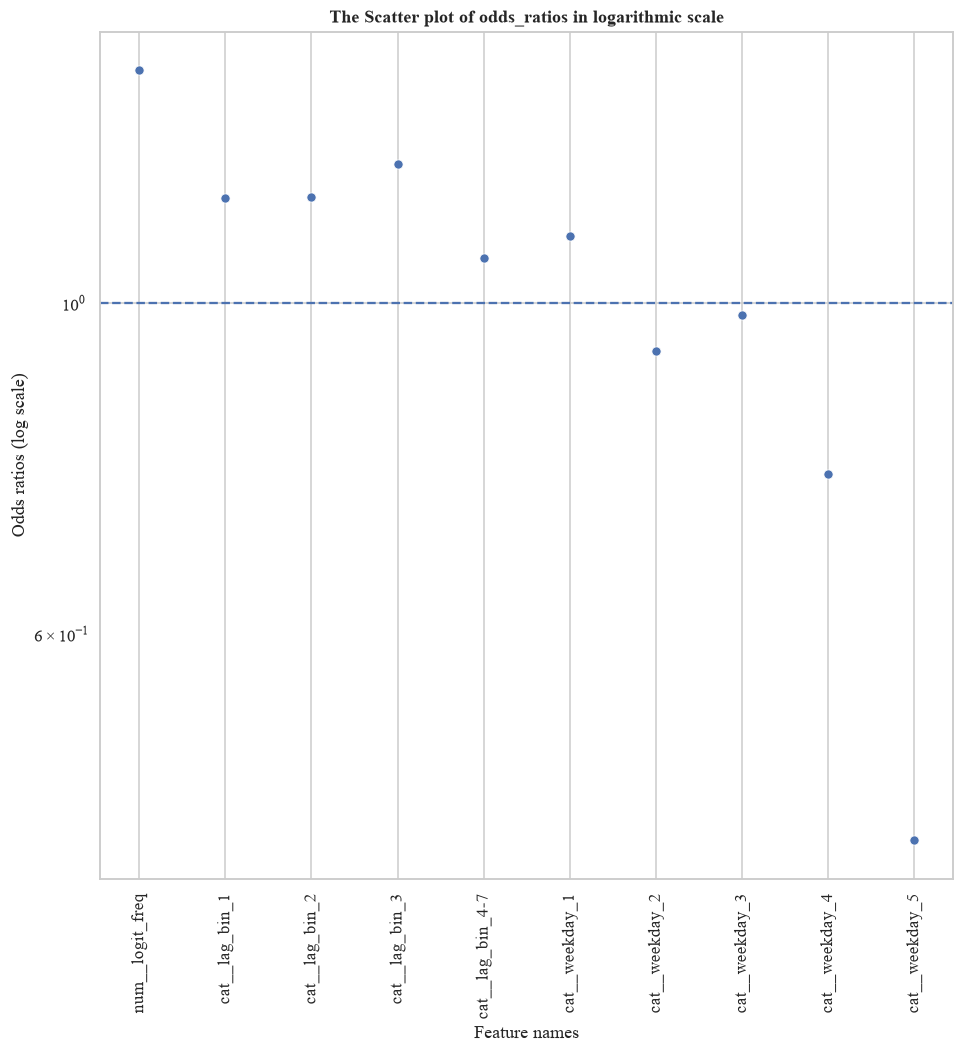

In [105]:
best = logistic.best_estimator_
# TODO: odds ratios (exp of the coefficients); hint: best[0].get_feature_names_out() gives the feature names, best[-1] is the LogisticRegression
feature_names = list(best[0].get_feature_names_out()) # The features names
odds_ratios = np.exp(best[-1].coef_).ravel() # The exp of the coefficients for each feature name
print(feature_names)
print(odds_ratios)
df_odds_ratios = pd.DataFrame({"feature_names": feature_names, "odds_ratios": odds_ratios})
display(odds_ratios)
# TODO: plot on a logarithmic axis with a reference line at 1
fig,ax = plt.subplots(figsize=(10,10))
sns.set_theme(style="whitegrid", font="Times New Roman")

sns.scatterplot(df_odds_ratios, x="feature_names", y="odds_ratios", ax=ax)
ax.set_title("The Scatter plot of odds_ratios in logarithmic scale",fontsize=12, fontweight="bold")
ax.set_ylabel("Odds ratios (log scale)",fontsize=12)
ax.set_xlabel("Feature names", fontsize=12)
ax.set_yscale("log")
ax.set_xticklabels(df_odds_ratios["feature_names"], rotation=90)
ax.axhline(y=1, label="reference line", linestyle="--")

plt.show()

## 4(f) - Calibration

Text(0, 0.5, 'True probability')

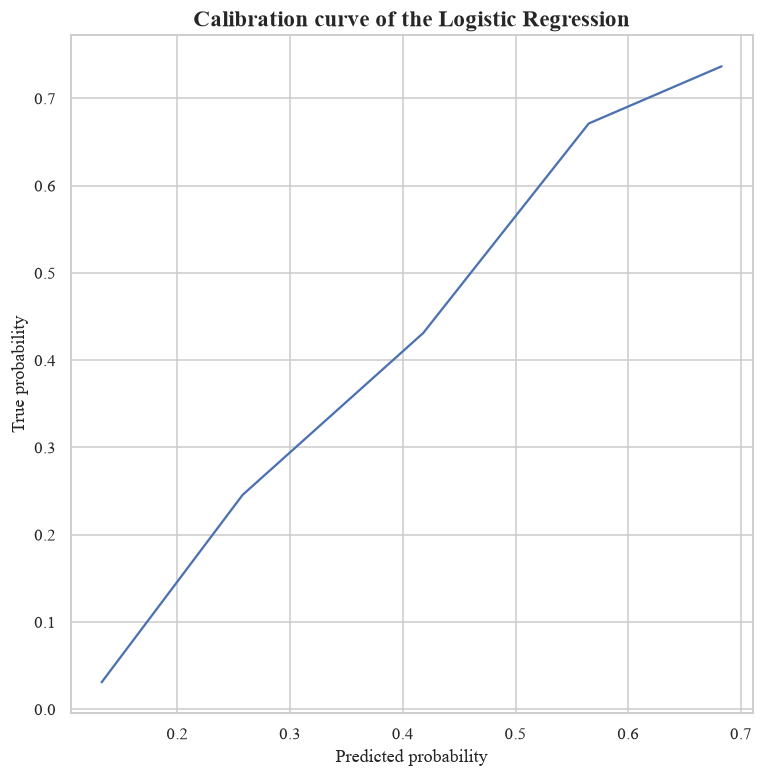

In [114]:
# TODO: calibration curves (6 bins) of the logistic regression and the MLP on the test set
logistic_prob_true, logistic_prob_pred = calibration_curve(y_true = test["hit"], y_prob=predictions["logistic regression"], n_bins=6)

fig, ax = plt.subplots(figsize=(8,8))
sns.set_theme(style="whitegrid", font="Times New Roman")

sns.lineplot(x=logistic_prob_pred, y=logistic_prob_true)
ax.set_title("Calibration curve of the Logistic Regression", fontsize=15, fontweight="bold")
ax.set_xlabel("Predicted probability") # The average predicted probability within each bin
ax.set_ylabel("True probability") # The observed fraction of hits within each bin

Text(0, 0.5, 'True probability')

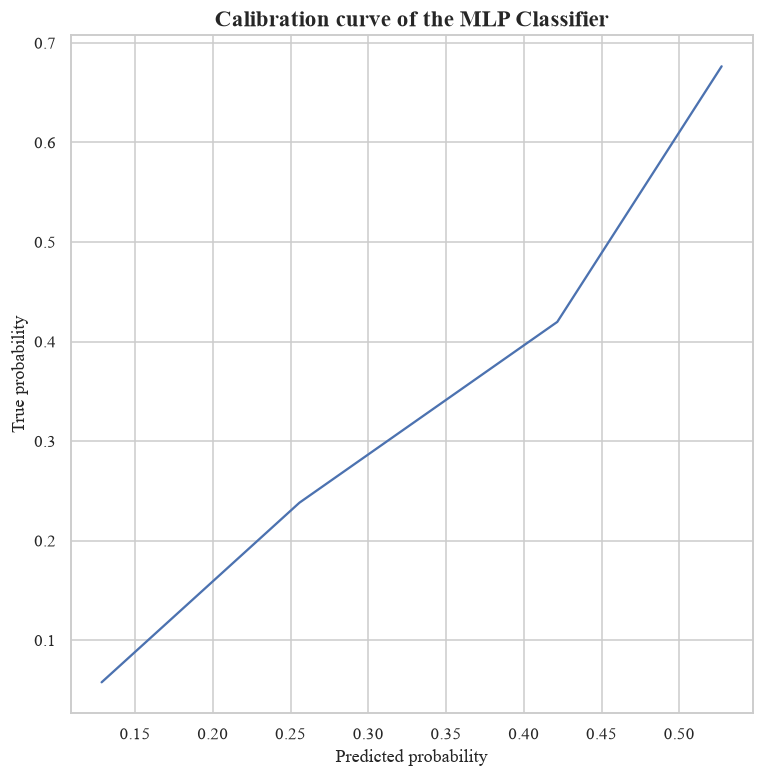

In [113]:
mlp_prob_true, mlp_prob_pred = calibration_curve(y_true = test["hit"], y_prob=predictions["mlp classifier"], n_bins=6)

# For example, a point at (0.6, 0.4) means the model predicted about 60% probability on average, but only 40% of those cases actually had a hit—it overestimated the probability.
fig, ax = plt.subplots(figsize=(8,8))
sns.set_theme(style="whitegrid", font="Times New Roman")

sns.lineplot(x=mlp_prob_pred, y=mlp_prob_true)
ax.set_title("Calibration curve of the MLP Classifier", fontsize=15, fontweight="bold")
ax.set_xlabel("Predicted probability") # The average predicted probability within each bin
ax.set_ylabel("True probability") # The observed fraction of hits within each bin

## 4(g) - Ablation study

Feature groups A (neighbours), B (time scales) and C (day level). All features use only earlier days.

### 4(g)(i) - Implementing the six features

OK: none of the 6 features uses information from later days.


,Datum,region,hit,logit_freq,lag_bin,weekday,logit_freq14,logit_freq180,n_prev,n_recent,gap,neigh_prev,split
0,2020-10-25,0,1,-0.367725,2,5,-0.251314,-0.367725,3,5.4,1,0.5,train
1,2020-10-25,1,0,-0.182322,1,5,0.251314,-0.182322,3,5.4,1,0.0,train
2,2020-10-25,2,1,-0.367725,4-7,5,-0.251314,-0.367725,3,5.4,1,0.5,train
3,2020-10-25,3,0,0.182322,1,5,0.788457,0.182322,3,5.4,1,0.0,train
4,2020-10-25,4,0,0.000000,3,5,0.251314,0.000000,3,5.4,1,0.5,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4683,2026-06-30,3,1,-0.064539,4-7,1,0.251314,-0.332706,7,3.8,1,1.0,test
4684,2026-06-30,4,0,-0.325422,1,1,0.251314,-0.493281,7,3.8,1,0.5,test
4685,2026-06-30,5,0,-0.392042,1,1,0.000000,-0.684917,7,3.8,1,1.0,test
4686,2026-06-30,6,0,-1.648659,8+,1,-1.466337,-1.747588,7,3.8,1,1.0,test


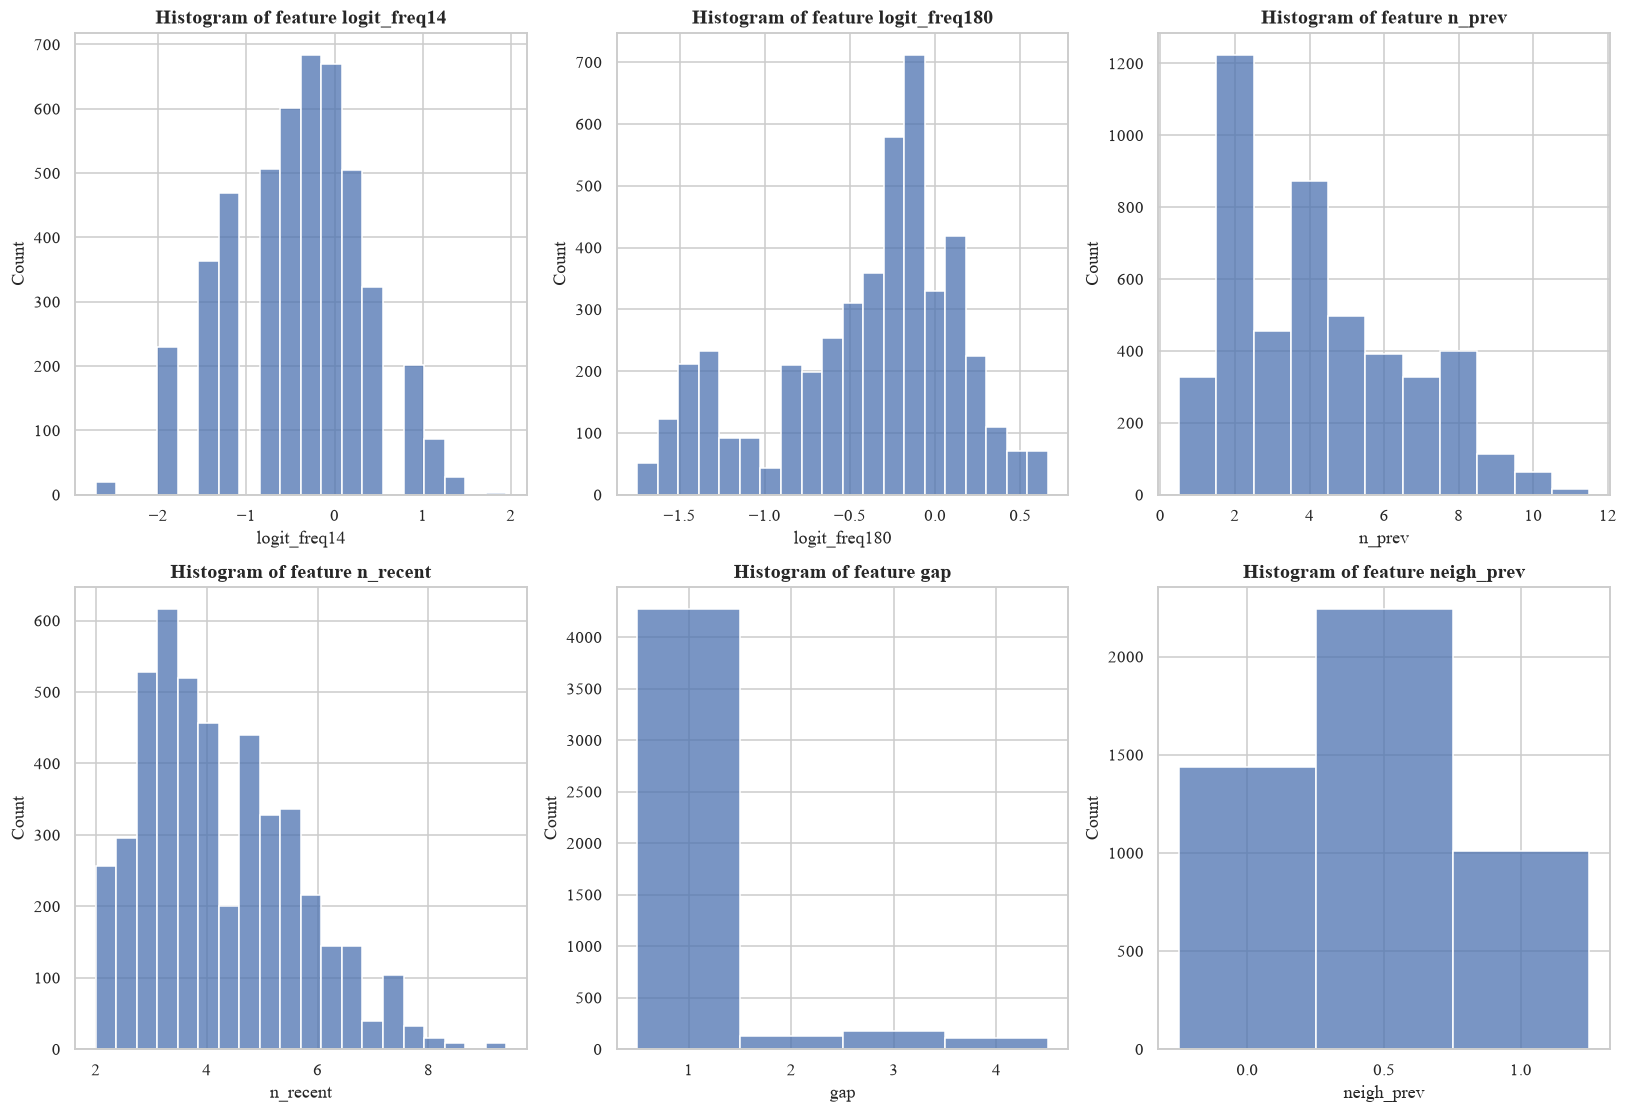

In [125]:
neighbours = helpers.region_neighbours(streets, region_of, n=2)   # dict: region -> its 2 nearest regions

def neigh_prev(hits: pd.DataFrame) -> pd.DataFrame:
    df_neigh_prev = pd.DataFrame(0.0, index=hits.index, columns=hits.columns)

    for i, idx in enumerate(hits.index):
        for col in hits.columns:
            if i > 0:
                df_neigh_prev.loc[idx, col] = hits.iloc[i-1][neighbours[col]].mean()

    return df_neigh_prev

def prev(hits: pd.DataFrame, n_traps:pd.Series) -> pd.Series:
    prev = pd.Series(0, index=hits.index)

    for i, idx in enumerate(n_traps.index):
        if i > 0:
            prev.loc[idx] = n_traps.iloc[i-1]

    return prev

def recent(hits: pd.DataFrame, n_traps:pd.Series) -> pd.Series:
    recent = pd.Series(0.0, index=hits.index)

    for i, idx in enumerate(n_traps.index):
        if i == 0:
            recent.loc[idx] = 0.0
        elif i - 5 < 0:
            recent.loc[idx] = n_traps.iloc[0:i].mean()
        else:
            recent.loc[idx] = n_traps.iloc[i-5:i].mean()

    return recent

def gap(hits: pd.DataFrame) -> pd.Series:
    gap = pd.Series(0, index=hits.index)

    for i, idx in enumerate(hits.index):
        if i > 0:
            gap.loc[idx] = min((idx - hits.index[i-1]).days, 4)

    return gap

def group_frames(hits: pd.DataFrame, n_traps: pd.Series) -> dict:
    # TODO: Implement the features from the table in the assignment's main sheet. Return {"logit_freq14", "logit_freq180", "n_prev", "n_recent", "gap", "neigh_prev"}, where each value is an array or a single-column dataframe
    #       (tables / Series in the same format as in base_frames; reuse rolling_freq)
    df_logit_freq_14 = logit(rolling_freq(hits, window=14))
    df_logit_freq_180 = logit(rolling_freq(hits, window=180))

    return {
        "logit_freq14": df_logit_freq_14,
        "logit_freq180": df_logit_freq_180,
        "n_prev": prev(hits, n_traps),
        "n_recent": recent(hits, n_traps),
        "gap": gap(hits),
        "neigh_prev": neigh_prev(hits)
    }

helpers.check_no_leakage(group_frames, hits, n_traps)
df = helpers.to_long({**base_frames(hits), **group_frames(hits, n_traps)}, hits)
train, test = (df[df["split"] == s] for s in ("train", "test"))
CV = helpers.time_splits(train)   # the training rows are the same as before; this only keeps `CV` consistent with `train`
# Backup: if you cannot implement the features, load them instead:
# df = pd.read_csv(DATA_DIR / "fallback_regression_k8.csv", parse_dates=["Datum"]); train, test = ...; CV = helpers.time_splits(train)
display(df)

# TODO: 2 x 3 figure with one histogram per new feature
fig,ax = plt.subplots(2,3, figsize=(18,12))
sns.set_theme(style="whitegrid", font="Times New Roman")

new_cols = ["logit_freq14", "logit_freq180", "n_prev", "n_recent", "gap", "neigh_prev"]

for i in range(6):
    col = new_cols[i]
    current_ax = ax[i // 3, i % 3]

    if col in ["n_prev", "gap"]:
        sns.histplot(df, x=col, ax=current_ax, discrete=True)
    elif col == "neigh_prev":
        sns.histplot(df, x=col, bins=[-0.25,0.25,0.75,1.25],ax=current_ax)
        current_ax.set_xticks([0,0.5,1])
    else:
        sns.histplot(df, x=col, bins=20, ax=current_ax)

    current_ax.set_title(f"Histogram of feature {col}",fontsize=13, fontweight="bold")

plt.show()

### 4(g)(ii) - Feature-group variants

Variants: base, +A, +B, +C, all. Tune the logistic regression over C for each variant and evaluate the test predictions.

In [128]:
GROUPS = {"+A": ["neigh_prev"], "+B": ["logit_freq14", "logit_freq180"], "+C": ["n_prev", "n_recent", "gap"]}
variants = {"base": [], **GROUPS, "all": sum(GROUPS.values(), [])}

ablation = {}
# TODO: for each variant, tune the logistic regression (numeric columns: BASE_NUM + the extra columns of the variant;
#       make_logistic and tune are defined in 4(d)) and store the test predictions in `ablation[name]`
print(tune(make_logistic(BASE_NUM), {"logisticregression__C" : [0.01,0.1,1.0]}).predict_proba(test))
ablation["base"] = tune(make_logistic(BASE_NUM), {"logisticregression__C" : [0.01,0.1,1.0]}).predict_proba(test)[:,1]
ablation["+A"] = tune(make_logistic(BASE_NUM + GROUPS["+A"]), {"logisticregression__C" : [0.01,0.1,1.0,10.0]}).predict_proba(test)[:,1]
ablation["+B"] = tune(make_logistic(BASE_NUM + GROUPS["+B"]), {"logisticregression__C" : [0.01,0.1,1.0,10.0]}).predict_proba(test)[:,1]
ablation["+C"] = tune(make_logistic(BASE_NUM + GROUPS["+C"]), {"logisticregression__C" : [0.01,0.1,1.0,10.0]}).predict_proba(test)[:,1]
helpers.evaluate(test, ablation).round(4)

[[0.57646959 0.42353041]
 [0.57646959 0.42353041]
 [0.59865381 0.40134619]
 ...
 [0.52624446 0.47375554]
 [0.75856215 0.24143785]
 [0.70066187 0.29933813]]


,log-loss,ROC AUC,day AUC
base,0.6048,0.7335,0.7081
+A,0.6024,0.7362,0.7086
+B,0.6016,0.7357,0.7179
+C,0.5938,0.7427,0.7096


### 4(g)(iii) - Discussion

*Answer in the report; no code needed.*

---
# Question 5 - Permutation Test (Bonus)

In [129]:
trap_days = pd.read_csv(DATA_DIR / "trap_deployments.csv", parse_dates=["Datum"])

M = pd.crosstab(trap_days["Datum"], trap_days["Strasse"]).clip(upper=1)   # measured day x street, 0/1
days = M.index
A = M.to_numpy(dtype=float)
a, b = helpers.lag_pairs(days, range(1, 8))                                 # all pairs of measured days 1-7 days apart (positions in `days`)
print(f"{A.shape[0]} measured days, {A.shape[1]} streets, {len(a)} day pairs with lag 1-7")

# Strata for the shuffling: measured days of the same month and the same type (weekend / working day) may exchange their street sets.
weekend = days.day_of_week >= 5
stratum = pd.factorize(pd.Series([f"{y}-{m}-{w}" for y, m, w in zip(days.year, days.month, weekend)]))[0]
print(len(set(stratum)), "strata")

606 measured days, 160 streets, 3592 day pairs with lag 1-7
47 strata


## 5(a) - Implementing the permutation test

`helpers.stratified_permutations(stratum, n, rng)` yields permutations `p`; the street set `A[p[i]]` is assigned to date `i`.

In [ ]:
N_PERM = 5000

def repeat_statistic(p: np.ndarray) -> float:
    # TODO: test statistic: mean number of shared streets per day pair (lag 1-7, index arrays `a` and `b`)
    #       if date i carries the street set A[p[i]]
    np.arange(p)


observed = ...   # statistic on the original data (hint: the identity permutation)
null = ...       # array with the statistic of N_PERM permutations (rng = np.random.default_rng(SEED))
p_value = ...    # one-sided p-value for "fewer shared streets than under H0"; hint: count the permutations <= observed
                 # and add 1 to numerator and denominator

# TODO: histogram of `null` with the observed value (vertical line) and the p-value;
#       also report the effect size, e.g. observed / null mean

## 5(b) - Relation to Question 4

*Answer in the report; no code needed.*